# Adversarial Distance Metrics in Clustering-Based Decision Systems

Reproducibility notebook for the extended version of the SECRYPT 2026 paper
*Adversarial Distance Metrics: A Threat to Fairness in Clustering-Based Decision Systems*
by Shahzad Ahmad, Stefan Rass and Enes Sovtic.

The notebook holds all code of the extended version. Clear old outputs first (*Kernel → Restart Kernel
and Clear Outputs of All Cells*), then run all cells (*Run → Run All Cells*). It reproduces every table, the figure and every
number in the text. Each experiment saves its results as a JSON file in `results/` and shows its
tables inline.

| Section | Paper | Output |
|---|---|---|
| 1. Setup | | package check, paths, run mode |
| 2. Data | Sect. 6 | Adult, COMPAS, German Credit (downloaded on first use) |
| 3. Construction | Sect. 4 | the ε-semimetric: conference algorithm and closed form |
| 4. Helpers | Sects. 5 and 6 | synthetic data, fairness statistics, attack partitions |
| 5. Experiment X1 | Sect. 4.5, Tables 1 and 2, Fig. 1 | `results/x1.json`, `results/fig1_time.png` |
| 6. Experiment X2 | Sect. 5, Tables 3 and 4 | `results/x2.json` |
| 7. Experiment X3 | Sect. 6, Tables 5 and 6 | `results/x3.json` |
| 8. Experiment X4 | Sect. 7.2, Table 7 | `results/x4.json` |
| 9. Numbers in the text | all sections | `results/numbers.json` |
| 10. Check | | comparison with the reference run of the paper |


**Runtime.** 25 to 45 minutes with the settings of the paper, depending on the machine. Most of it
is the conference algorithm at m = 70 in X1. Set `QUICK = True` in Section 1 to run every code path
with smaller sizes in a few minutes. Quick results go to `results_quick/` and never overwrite the
results of the paper.

**Memory.** The closed form at m = 150 in X1 needs about 3 GB.

## 1. Setup

The first cell installs missing packages into the running kernel, imports everything and fixes the
run mode. `QUICK = True` runs every experiment with smaller sizes. `RECOMPUTE = False` loads the
JSON files of an earlier run instead of recomputing them, which renders all tables in seconds.

In [1]:
import hashlib
import importlib.util
import json
import math
import os
import subprocess
import sys
import time
import urllib.request
import warnings
from collections import defaultdict
from importlib.metadata import version
from pathlib import Path

# Install missing packages into the running kernel.
REQUIRED = {"numpy": "numpy", "scipy": "scipy", "sklearn": "scikit-learn", "pandas": "pandas",
            "matplotlib": "matplotlib", "kmedoids": "kmedoids"}
_missing = [pip for module, pip in REQUIRED.items() if importlib.util.find_spec(module) is None]
if _missing:
    print("installing", " ".join(_missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)

import kmedoids
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import scipy.io as sio
import sklearn
from IPython.display import Markdown, display
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.linalg import lu_factor, lu_solve, qr, qr_delete
from scipy.linalg.lapack import dgecon
from scipy.spatial.distance import cdist, squareform
from sklearn.cluster import DBSCAN, HDBSCAN, OPTICS, AgglomerativeClustering, KMeans, SpectralClustering
from sklearn.metrics import adjusted_rand_score

try:
    from joblib.externals.loky.backend import context as _loky_ctx
    if getattr(_loky_ctx, "physical_cores_cache", None) is None:
        try:
            import psutil
            _physical = psutil.cpu_count(logical=False)
        except Exception:
            _physical = None
        _loky_ctx.physical_cores_cache = _physical or os.cpu_count() or 1
except Exception:
    pass

warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak on Windows with MKL")

# ------------------------------------------------------------------------------------- run mode
QUICK = False      # True: smaller sizes, a few minutes. False: the settings of the paper.
RECOMPUTE = True   # False: load the JSON files of an earlier run instead of recomputing them.

ROOT = Path.cwd()                      # the folder that holds this notebook
DATA = ROOT / "data"
ARTIFACTS = DATA / "artifacts"
RESULTS = ROOT / ("results_quick" if QUICK else "results")
for _p in (DATA, ARTIFACTS, RESULTS):
    _p.mkdir(parents=True, exist_ok=True)

print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | SciPy {scipy.__version__} | "
      f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | matplotlib {matplotlib.__version__} | "
      f"kmedoids {version('kmedoids')}")
print(f"mode: {'QUICK' if QUICK else 'paper settings'} | output folder: {RESULTS.relative_to(ROOT)}")


def save_json(name, obj):
    with open(RESULTS / name, "w") as f:
        json.dump(obj, f, indent=1)


def load_json(name):
    path = RESULTS / name
    return json.load(open(path)) if path.exists() else None


def run_or_load(name, fn):
    """Run an experiment and save its results, or load an earlier run when RECOMPUTE is False."""
    if not RECOMPUTE and (RESULTS / name).exists():
        print(f"loaded {(RESULTS / name).relative_to(ROOT)}")
        return load_json(name)
    t0 = time.perf_counter()
    res = fn()
    save_json(name, res)
    print(f"saved {(RESULTS / name).relative_to(ROOT)} after {time.perf_counter() - t0:.0f} s")
    return res


def show_table(title, header, rows):
    """Render a table as Markdown."""
    md = [f"**{title}**", "", "| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    md += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    display(Markdown("\n".join(md)))

Python 3.12.4 | NumPy 1.26.4 | SciPy 1.14.1 | scikit-learn 1.5.1 | pandas 2.2.2 | matplotlib 3.9.2 | kmedoids 0.5.5
mode: paper settings | output folder: results


## 2. Data

Three fairness benchmarks. The cell downloads each file into `data/` on first use and checks its
SHA-256 against the file the paper used. Without network access, put the files into `data/` by hand.

| File | Source | Protected group | Favourable outcome |
|---|---|---|---|
| `adult.data` | UCI Machine Learning Repository, Adult (Becker and Kohavi, 1996), CC BY 4.0 | Black (reference: White) | income above 50K |
| `compas-scores-two-years.csv` | ProPublica, `propublica/compas-analysis` on GitHub (Larson et al., 2016) | African-American (reference: Caucasian) | no recidivism within two years |
| `german.data` | UCI Machine Learning Repository, Statlog German Credit (Hofmann, 1994), CC BY 4.0 | female (reference: male) | good credit |

COMPAS uses the filter of the ProPublica analysis. The experiments standardise the features listed in
`FEATURES`. The conference Adult experiment uses ten records that Section 4 lists explicitly.

`data/artifacts/As_m12_double.mat` is the quadratic form that the MATLAB code of the conference
paper saved for its Adult experiment. X1 compares against it. Without it, X1 falls back to the same
algorithm run in Python.

In [2]:
SOURCES = {
    "adult.data": ("https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
                   "5b00264637dbfec36bdeaab5676b0b309ff9eb788d63554ca0a249491c86603d"),
    "german.data": ("https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data",
                    "b21f3d81db8071257d5ff1deaeba1fd4303b62712e6fcc9715c7a86202cb5871"),
    "compas-scores-two-years.csv": (
        "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv",
        "c451db85908b2f7fef1d83203bedf6b71ecda0d5af468d82ae62178f91d0cc7d"),
}


def fetch(name):
    """Path of a data file. Downloads it first if it is missing and checks its SHA-256."""
    path = DATA / name
    url, sha = SOURCES[name]
    if not path.exists():
        print(f"downloading {name} from {url}")
        try:
            with urllib.request.urlopen(url, timeout=120) as r:
                path.write_bytes(r.read())
        except Exception as e:
            raise RuntimeError(f"Download of {name} failed ({e}). Get it from {url} and put it into {DATA}.")
    if hashlib.sha256(path.read_bytes()).hexdigest() != sha:
        print(f"warning: {name} differs from the file used in the paper, so results may differ")
    return path


def adult(n=None, seed=0):
    cols = ["age", "workclass", "fnlwgt", "education", "education_num", "marital", "occupation",
            "relationship", "race", "sex", "capital_gain", "capital_loss", "hours", "country", "income"]
    df = pd.read_csv(fetch("adult.data"), header=None, names=cols, skipinitialspace=True, na_values="?")
    df = df[df["race"].isin(["White", "Black"])].reset_index(drop=True)
    if n is not None and n < len(df):
        df = df.sample(n=n, random_state=seed).reset_index(drop=True)
    X = np.column_stack([df["age"], df["education_num"], df["hours"],
                         np.log1p(df["capital_gain"]), np.log1p(df["capital_loss"])]).astype(float)
    return dict(name="Adult", X=X, names=["age", "education", "hours/week", "log capital gain", "log capital loss"],
                a=(df["race"] == "Black").to_numpy().astype(int),
                ylab=(df["income"].str.strip() == ">50K").to_numpy().astype(int), groups=("Black", "White"))


def compas():
    df = pd.read_csv(fetch("compas-scores-two-years.csv"))
    df = df[(df["days_b_screening_arrest"] <= 30) & (df["days_b_screening_arrest"] >= -30)
            & (df["is_recid"] != -1) & (df["c_charge_degree"] != "O") & (df["score_text"] != "N/A")]
    df = df[df["race"].isin(["African-American", "Caucasian"])].reset_index(drop=True)
    juv = df["juv_fel_count"] + df["juv_misd_count"] + df["juv_other_count"]
    X = np.column_stack([df["age"], df["priors_count"], juv, (df["c_charge_degree"] == "F").astype(int)]).astype(float)
    return dict(name="COMPAS", X=X, names=["age", "priors", "juvenile counts", "felony charge"],
                a=(df["race"] == "African-American").to_numpy().astype(int),
                ylab=(df["two_year_recid"] == 0).to_numpy().astype(int), groups=("African-American", "Caucasian"))


def german():
    df = pd.read_csv(fetch("german.data"), header=None, sep=r"\s+")
    X = np.column_stack([df[1], np.log(df[4]), df[7], df[10], df[12], df[15]]).astype(float)
    return dict(name="German Credit", X=X,
                names=["duration", "log amount", "installment rate", "residence", "age", "credits"],
                a=df[8].isin(["A92", "A95"]).to_numpy().astype(int),
                ylab=(df[20] == 1).to_numpy().astype(int), groups=("female", "male"))


def standardize(X):
    mu, sd = X.mean(0), X.std(0, ddof=0)
    sd[sd == 0] = 1.0
    return (X - mu) / sd


LOADERS = {"Adult": adult, "COMPAS": compas, "German Credit": german}
FEATURES = {"Adult": [0, 1, 2], "COMPAS": [0, 1, 2, 3], "German Credit": [0, 1, 2, 3, 4, 5]}
DATASETS = list(LOADERS)


def load_dataset(name):
    d = LOADERS[name]()
    d["names"] = [d["names"][k] for k in FEATURES[name]]
    d["X"] = standardize(d["X"][:, FEATURES[name]])
    return d


def sample_distinct(d, m, seed):
    """m individuals with pairwise distinct standardised feature vectors."""
    r = np.random.default_rng(seed)
    idx, seen = [], set()
    for i in r.permutation(len(d["X"])):
        key = tuple(np.round(d["X"][i], 12))
        if key not in seen:
            seen.add(key)
            idx.append(i)
            if len(idx) == m:
                break
    idx = np.array(idx)
    return d["X"][idx], d["a"][idx], d["ylab"][idx]


for _name in DATASETS:
    _d = load_dataset(_name)
    print(f"{_name}: {len(_d['X'])} individuals, features {', '.join(_d['names'])}, protected group "
          f"{_d['groups'][0]} ({_d['a'].sum()}), favourable rate {_d['ylab'].mean():.3f}")

Adult: 30940 individuals, features age, education, hours/week, protected group Black (3124), favourable rate 0.243
COMPAS: 5278 individuals, features age, priors, juvenile counts, felony charge, protected group African-American (3175), favourable rate 0.530
German Credit: 1000 individuals, features duration, log amount, installment rate, residence, age, credits, protected group female (310), favourable rate 0.700


## 3. The ε-semimetric construction (Sect. 4)

**Lifting.** Every pair of points (x, y) maps to the lifted difference
v(x, y) = (x − y, s·(f(x, y) − f(y, x))) in ℝ^h with h = m(m − 1)/2. The noise f(x, y) ∈ [0, 1)^(h−ℓ)
comes from a pseudorandom generator seeded by the coordinates, exactly as in the MATLAB code of the
conference paper. For positive seeds, MATLAB's `rng(seed)` and NumPy's `RandomState(seed)` produce
the same Mersenne Twister stream, and MATLAB's `int32()` rounds half away from zero. The noise scale
is s = 0.9 ε/√h.

**Norm.** The function is d̃(x, y) = ‖v(x, y)‖_q with ‖u‖_q = √(uᵀAu), where A makes
‖v_k‖_q = δ_k for every data pair k. The conference algorithm builds A from h null spaces with
one QR update each (`conference_A`). Proposition 1 gives the closed form
A = V^(−T) Δ² V^(−1) with V = [v_1, …, v_h] and Δ = diag(δ). The class `EpsSemimetric` evaluates
d̃(x, y) = ‖Δ V^(−1) v(x, y)‖₂ through one LU factorisation of V and never forms A.

**Targets.** `two_level_targets` builds the three target designs of the paper. The *unclipped*
targets of the conference benchmarks are 0.005 d_min inside a cluster and 200 d_max across clusters.
The *clipped* targets of the conference experiments cap these values at 0.99 times the Euclidean
distance. The *constant* targets of Proposition 3 use s₀ = 0.005 d_min inside and one value
D = 0.99 · (smallest cross-cluster distance) across clusters.

In [3]:
def matlab_seed(a, b):
    """seed = int32(|prod(a) * sum(b)| / 10^floor(log10(.)) * 1e8), as in compute_metric.m."""
    v = abs(float(np.prod(a)) * float(np.sum(b)))
    if v == 0.0 or not math.isfinite(v):
        return 5489                       # MATLAB's rng(0) seeds the Mersenne Twister with 5489
    v = v / 10.0 ** math.floor(math.log10(v)) * 1e8
    return int(math.floor(v + 0.5))


def lift(a, b, s, h):
    """v = z_a - z_b with z_a = [a, s * rand(h - ell)] seeded by (a, b), as in epsilon_semimetric.m."""
    a = np.asarray(a, float)
    b = np.asarray(b, float)
    extra = h - len(a)
    za = np.concatenate([a, s * np.random.RandomState(matlab_seed(a, b)).random_sample(extra)])
    zb = np.concatenate([b, s * np.random.RandomState(matlab_seed(b, a)).random_sample(extra)])
    return za - zb


def pair_list(m):
    """All pairs i < j in the loop order of the MATLAB code."""
    return [(i, j) for i in range(m) for j in range(i + 1, m)]


def lifted_matrix(Y, s):
    m = len(Y)
    h = m * (m - 1) // 2
    return np.column_stack([lift(Y[i], Y[j], s, h) for i, j in pair_list(m)])


def euclid(Y):
    return np.linalg.norm(Y[:, None, :] - Y[None, :, :], axis=2)


def two_level_targets(Y, labels, mode="constant", small_factor=0.005, large_factor=200.0):
    """Targets for a partition, as a square matrix T and as a vector in pair order.

    constant:  s0 = 0.005 d_min inside a cluster, one value D = 0.99 * (smallest cross-cluster
               distance) across clusters (Proposition 3).
    clipped:   min(s0 or 200 d_max, 0.99 * Euclidean distance), the conference experiments.
    unclipped: s0 inside, 200 d_max across, the conference benchmarks.
    """
    E = euclid(Y)
    m = len(Y)
    iu = np.triu_indices(m, 1)
    d_min, d_max = E[iu].min(), E[iu].max()
    same = labels[:, None] == labels[None, :]
    s0 = small_factor * d_min
    if mode == "constant":
        T = np.where(same, s0, 0.99 * E[~same].min())
    elif mode == "clipped":
        T = np.minimum(np.where(same, s0, large_factor * d_max), 0.99 * E)
    elif mode == "unclipped":
        T = np.where(same, s0, large_factor * d_max)
    else:
        raise ValueError(mode)
    np.fill_diagonal(T, 0.0)
    return T, np.array([T[i, j] for i, j in pair_list(m)]), d_min


def triangle_defect(T):
    """tau(T) = max over pairwise distinct i, j, k of T_ij - T_ik - T_kj (Definition 3)."""
    best = -np.inf
    for k in range(len(T)):
        D = T - T[:, [k]] - T[[k], :]
        D[k, :] = -np.inf
        D[:, k] = -np.inf
        np.fill_diagonal(D, -np.inf)
        best = max(best, float(D.max()))
    return best


def square(m, vec):
    """Square symmetric matrix from values in pair order."""
    T = np.zeros((m, m))
    for (i, j), v in zip(pair_list(m), vec):
        T[i, j] = T[j, i] = v
    return T


def conference_A(V, delta):
    """The null-space algorithm of compute_metric.m (double precision, one QR update per pair)."""
    h = V.shape[0]
    Q_full, R_full = qr(V)
    A = np.zeros((h, h))
    for i in range(h):
        Q, _ = qr_delete(Q_full, R_full, i, 1, which="col")
        w = Q[:, -1]                       # spans the orthogonal complement of the other columns
        A_i = np.outer(w, w)
        A += A_i / (V[:, i] @ A_i @ V[:, i]) * delta[i] ** 2
    return A


class EpsSemimetric:
    """d~(x, y) = ||(x, s f(x,y)) - (y, s f(y,x))||_q with the closed-form norm of Proposition 1.

    Y: data (m x ell), delta: targets in pair order, eps: tolerance, which fixes the noise scale
    s = 0.9 eps / sqrt(h) as in compute_metric.m.
    """

    def __init__(self, Y, delta, eps):
        self.Y = np.asarray(Y, float)
        self.m, self.ell = self.Y.shape
        self.h = self.m * (self.m - 1) // 2
        self.delta = np.asarray(delta, float)
        self.eps = eps
        self.s = 0.9 * eps / math.sqrt(self.h)
        self.V = lifted_matrix(self.Y, self.s)
        self.lu = lu_factor(self.V)

    def lifted(self, x, y):
        return lift(x, y, self.s, self.h)

    def dist(self, x, y):
        """Stable evaluation ||diag(delta) V^{-1} v(x, y)||_2."""
        return float(np.linalg.norm(self.delta * lu_solve(self.lu, self.lifted(x, y))))

    def dists_lifted(self, Vcols):
        """Stable evaluation for many lifted vectors, given as columns."""
        return np.linalg.norm(self.delta[:, None] * lu_solve(self.lu, Vcols), axis=0)

    def on_data(self):
        """Realised values on all data pairs, in pair order."""
        return self.dists_lifted(self.V)

    def explicit_A(self):
        """A = V^{-T} diag(delta)^2 V^{-1}, formed explicitly (for comparisons only)."""
        W = self.delta[:, None] * lu_solve(self.lu, np.eye(self.h))
        return W.T @ W

    def cond1_estimate(self):
        """1-norm condition number of V, estimated by LAPACK dgecon from the LU factors."""
        anorm = float(np.abs(self.V).sum(axis=0).max())
        rcond, _ = dgecon(self.lu[0], anorm, norm="1")
        return float("inf") if rcond == 0 else 1.0 / float(rcond)


# A small demonstration: three clusters in the plane, eps = d_min / 10.
_Y = np.random.default_rng(0).standard_normal((12, 2))
_lab = np.repeat([1, 2, 3], 4)
_T, _delta, _dmin = two_level_targets(_Y, _lab, mode="constant")
_E = EpsSemimetric(_Y, _delta, _dmin / 10)
print(f"m = 12, h = {_E.h}: largest relative error on the data pairs "
      f"{np.max(np.abs(_E.on_data() - _delta) / _delta):.1e}, triangle defect of the targets "
      f"{triangle_defect(_T) / _E.eps:+.3f} eps")
print(f"closed form versus conference algorithm: relative difference "
      f"{np.abs(_E.explicit_A() - conference_A(_E.V, _delta)).max() / np.abs(_E.explicit_A()).max():.1e}")

m = 12, h = 66: largest relative error on the data pairs 1.5e-15, triangle defect of the targets -0.050 eps
closed form versus conference algorithm: relative difference 7.0e-15


## 4. Helpers for the experiments

* `synthetic` follows `benchmark_clustering.m` of the conference paper: m − 3 standard normal points
  in ℝ², random labels in {1, 2, 3}, and the three cluster centres added as extra points. NumPy's normal
  generator differs from MATLAB's, so the points differ from the conference draws.
* `adult_conference` rebuilds the ten Adult records and the augmented data of the conference experiment
  (`Adversarial_Distance_Metrics.m`), including its micro-jitter.
* Fairness statistics: the signed demographic parity difference DPD = P(fav | reference) − P(fav | protected),
  the disparate-impact ratio DI = P(fav | protected) / P(fav | reference) and the equalised-odds
  difference EOD. The DPD interval comes from 2000 bootstrap resamples.
* `honest_and_attacks` runs the honest k-medoids pipeline (FasterPAM, k = 2, BUILD, one thread) and
  builds the two attack partitions of Sect. 6.2. The pipeline calls the cluster with the higher rate of
  favourable outcomes favourable.
  * *Targeted attack:* moves the g protected members of the favourable cluster that lie closest to the
    unfavourable medoid. g is the largest number of moves that keeps the DPD inside the honest 95%
    bootstrap interval and keeps the favourable cluster favourable.
  * *Maximal attack:* puts every protected individual into the unfavourable cluster and everyone else
    into the favourable one. If the protected group has the higher rate of favourable outcomes in a
    sample, the adversary also moves the fewest reference individuals with an unfavourable outcome into
    the protected cluster, until that cluster has the lower rate.

In [4]:
def synthetic(m, seed, ell=2, k=3, min_size=2):
    """m - k Gaussian points, random labels with at least min_size points each, k centres prepended."""
    r = np.random.default_rng(seed)
    Y = r.standard_normal((m - k, ell))
    while True:
        lab = r.integers(1, k + 1, m - k)
        if (np.bincount(lab, minlength=k + 1)[1:] >= min_size).all():
            break
    C = np.array([Y[lab == c].mean(0) for c in range(1, k + 1)])
    return np.vstack([C, Y]), np.concatenate([np.arange(1, k + 1), lab])


ADULT_RAW = np.array([  # age, education_num, hours_per_week, race_white, income_high
    [26, 15, 20, 1, 0], [66, 9, 24, 1, 1], [45, 14, 40, 1, 1], [46, 4, 40, 1, 0],
    [55, 10, 50, 1, 0], [81, 5, 16, 0, 0], [27, 9, 40, 0, 0], [41, 12, 40, 0, 1],
    [33, 12, 55, 0, 0], [53, 11, 48, 0, 0]], dtype=float)


def adult_conference():
    """The inputs of Adversarial_Distance_Metrics.m: y, the augmented data y_aug and the labels."""
    X = ADULT_RAW[:, :3]
    y = (X - X.mean(0)) / X.std(0, ddof=1)                  # MATLAB's std uses N - 1
    m = len(y)
    y = y + (np.arange(1, m + 1) * 1e-8)[:, None]           # micro-jitter of the MATLAB code
    adv = np.where(ADULT_RAW[:, 3] == 1, 1, 2)              # White -> cluster 1, Black -> cluster 2
    C = np.array([y[adv == c].mean(0) for c in (1, 2)])
    y_aug = np.vstack([C, y])
    y_aug[:2] += (np.array([m + 1, m + 2]) * 1e-8)[:, None]
    return dict(y=y, y_aug=y_aug, labels_aug=np.concatenate([[1, 2], adv]),
                white=ADULT_RAW[:, 3].astype(int), high=ADULT_RAW[:, 4].astype(int))


def rates(fav, a):
    return fav[a == 1].mean(), fav[a == 0].mean()


def dpd(fav, a):
    """Reference minus protected. A positive value means that the protected group is disadvantaged."""
    p1, p0 = rates(fav, a)
    return p0 - p1


def di(fav, a):
    p1, p0 = rates(fav, a)
    return p1 / p0 if p0 > 0 else float("nan")


def eod(fav, a, y):
    """Equalised-odds difference: max over y in {0, 1} of |P(fav | a=0, y) - P(fav | a=1, y)|."""
    out = 0.0
    for v in (0, 1):
        s0 = (a == 0) & (y == v)
        s1 = (a == 1) & (y == v)
        if s0.sum() and s1.sum():
            out = max(out, abs(fav[s0].mean() - fav[s1].mean()))
    return out


def bootstrap_dpd(fav, a, B=2000, seed=0):
    """95% percentile interval of the DPD over B resamples that contain both groups."""
    r = np.random.default_rng(seed)
    n = len(fav)
    vals = []
    while len(vals) < B:
        i = r.integers(0, n, n)
        if a[i].sum() and (1 - a[i]).sum():
            vals.append(dpd(fav[i], a[i]))
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return float(lo), float(hi)


def kmed(D, k=2):
    """FasterPAM, single-threaded, BUILD initialisation."""
    r = kmedoids.fasterpam(D, k, init="build", random_state=0, n_cpu=1)
    return np.asarray(r.labels), np.asarray(r.medoids)


def honest_and_attacks(X, a, ylab, seed):
    """Honest k-medoids decisions and the two attack partitions (1 = favourable cluster)."""
    E = euclid(X)
    lab, med = kmed(E)
    F = int(np.argmax([ylab[lab == c].mean() for c in (0, 1)]))
    fav = (lab == F).astype(int)
    lo, hi = bootstrap_dpd(fav, a, seed=seed)
    n_p = int(a.sum())
    mu_F, mu_U = X[med[F]], X[med[1 - F]]
    cand = np.where((a == 1) & (fav == 1))[0]
    # each move raises the DPD by 1/n_p: the largest number of moves that stays inside the interval
    g_res = int(math.floor((hi - dpd(fav, a)) * n_p + 1e-9))
    beta = np.linalg.norm(X[cand] - mu_U, axis=1) / np.maximum(np.linalg.norm(X[cand] - mu_F, axis=1), 1e-12)
    order = cand[np.argsort(beta)]
    g = min(max(g_res, 0), len(order))
    while True:
        # the moves must not reverse which cluster has the higher rate of favourable outcomes
        part_t = fav.copy()
        part_t[order[:g]] = 0
        if g == 0 or ylab[part_t == 1].mean() > ylab[part_t == 0].mean():
            break
        g -= 1
    part_m = (1 - a).copy()
    ref_bad = np.where((a == 0) & (ylab == 0))[0]
    moved = 0
    while ylab[part_m == 0].mean() >= ylab[part_m == 1].mean() and moved < len(ref_bad):
        part_m[ref_bad[moved]] = 0
        moved += 1
    info = dict(n_protected=n_p, n_protected_fav=int(len(cand)), dpd=dpd(fav, a), dpd_lo=lo, dpd_hi=hi,
                di=di(fav, a), eod=eod(fav, a, ylab), g_res=int(g_res), g=int(g), maximal_moved_reference=int(moved))
    return fav, part_t, part_m, info

## 5. Experiment X1: closed form, accuracy and cost (Sect. 4.5, Tables 1 and 2, Fig. 1)

(a) The conference algorithm in Python reproduces the matrix that the MATLAB code saved for the Adult
experiment, and the closed form equals both, on this instance and on synthetic data. (b) Accuracy on the
data pairs: the conference algorithm evaluates √(vᵀAv) with an explicit A, and the closed form evaluates
‖ΔV⁻¹v‖₂ with an LU factorisation. (c) Construction time of both, and the time of one query. Timings
depend on the machine.

In [5]:
X1_ACCURACY_M = (10, 20, 30) if QUICK else (10, 20, 30, 40, 50, 60)
X1_CONF_TIME_M = (10, 20, 30, 40) if QUICK else (10, 20, 30, 40, 50, 60, 70)
X1_LU_TIME_M = (10, 20, 30, 40, 50, 70) if QUICK else (10, 20, 30, 40, 50, 60, 70, 100, 130, 150)
CONFERENCE_MATLAB_SECONDS = {"10": 0.022, "20": 0.12, "30": 0.63, "40": 3.6, "50": 23, "60": 71, "70": 345,
                             "80": 616, "90": 1246, "100": 2348, "110": 4112, "120": 6863, "130": 11038}


def run_x1():
    res = {}
    # (a) closed form versus the conference algorithm
    ad = adult_conference()
    _, d_clip, d_min = two_level_targets(ad["y_aug"], ad["labels_aug"], mode="clipped")
    E = EpsSemimetric(ad["y_aug"], d_clip, d_min / 10)
    mat = ARTIFACTS / "As_m12_double.mat"
    A_python = conference_A(E.V, d_clip)                     # compute_metric.m, run in Python
    A_ref = sio.loadmat(mat)["A"].astype(float) if mat.exists() else A_python
    rel_syn = {}
    for m in (10, 20, 30):
        Y, lab = synthetic(m, 1000 * m)
        _, delta, dm = two_level_targets(Y, lab, mode="constant")
        Es = EpsSemimetric(Y, delta, dm / 10)
        Ac = conference_A(Es.V, delta)
        rel_syn[str(m)] = float(np.abs(Es.explicit_A() - Ac).max() / np.abs(Ac).max())
    res["closed_form"] = dict(adult_saved_rel=float(np.abs(E.explicit_A() - A_ref).max() / np.abs(A_ref).max()),
                              adult_reference="saved MATLAB matrix" if mat.exists() else "conference algorithm",
                              python_conference_vs_saved_rel=(float(np.abs(A_python - A_ref).max() / np.abs(A_ref).max())
                                                              if mat.exists() else None),
                              synthetic_rel=rel_syn)
    print("closed form versus conference algorithm:", res["closed_form"])

    # (b) accuracy on the data pairs
    rows = []
    for mode in ("unclipped", "constant"):
        for m in X1_ACCURACY_M:
            for seed in (0, 1):
                Y, lab = synthetic(m, 1000 * m + seed)
                _, delta, dm = two_level_targets(Y, lab, mode=mode)
                Es = EpsSemimetric(Y, delta, dm / 10)
                stable = Es.on_data()
                Ac = conference_A(Es.V, delta)
                q = np.einsum("ij,ij->j", Es.V, Ac @ Es.V)          # v' A v for every data pair
                ok = q >= 0
                rel_conf = np.abs(np.sqrt(np.where(ok, q, 0.0)) - delta) / delta
                same = np.array([lab[i] == lab[j] for i, j in pair_list(m)])
                rows.append(dict(mode=mode, m=m, seed=seed, h=Es.h, condV=float(np.linalg.cond(Es.V)),
                                 ratio=float(delta.max() / delta.min()),
                                 conf_imag=int((~ok).sum()), conf_imag_intra=int((~ok & same).sum()),
                                 n_intra=int(same.sum()),
                                 conf_relerr_median=float(np.median(rel_conf[ok])),
                                 conf_relerr_max=float(rel_conf[ok].max()),
                                 stable_relerr_max=float((np.abs(stable - delta) / delta).max())))
                print(f"accuracy {mode:9s} m={m:3d} seed={seed}: complex {rows[-1]['conf_imag']:4d}/{Es.h}, "
                      f"explicit rel. err. {rows[-1]['conf_relerr_max']:.1e}, stable rel. err. "
                      f"{rows[-1]['stable_relerr_max']:.1e}")
    res["accuracy"] = rows

    # (c) construction time
    tc = []
    for m in X1_CONF_TIME_M:
        Y, lab = synthetic(m, 1000 * m)
        _, delta, dm = two_level_targets(Y, lab, mode="constant")
        t0 = time.perf_counter()
        Es = EpsSemimetric(Y, delta, dm / 10)
        t_lift = time.perf_counter() - t0
        t0 = time.perf_counter()
        conference_A(Es.V, delta)
        t_conf = time.perf_counter() - t0
        tc.append(dict(m=m, lift=t_lift, conference=t_conf))
        print(f"conference algorithm m={m:3d}: {t_lift + t_conf:.2f} s")
    tl = []
    rng = np.random.default_rng(5)
    for m in X1_LU_TIME_M:
        Y, lab = synthetic(m, 1000 * m)
        _, delta, dm = two_level_targets(Y, lab, mode="constant")
        t0 = time.perf_counter()
        Es = EpsSemimetric(Y, delta, dm / 10)
        t_build = time.perf_counter() - t0
        P = rng.uniform(Y.min(0), Y.max(0), size=(100, Y.shape[1]))
        Vq = np.column_stack([lift(P[i], Y[i % m], Es.s, Es.h) for i in range(100)])
        t0 = time.perf_counter()
        Es.dists_lifted(Vq)
        t_q = (time.perf_counter() - t0) / 100
        idx = rng.choice(Es.h, min(Es.h, 1000), replace=False)
        err = float(np.max(np.abs(Es.dists_lifted(Es.V[:, idx]) - delta[idx]) / delta[idx]))
        tl.append(dict(m=m, h=Es.h, build=t_build, query=t_q, relerr_max=err))
        print(f"closed form          m={m:3d}: build {t_build:.2f} s, query {1000 * t_q:.2f} ms, rel. err. {err:.1e}")
        del Es
    res["time_conference_algorithm"] = tc
    res["time_closed_form"] = tl
    res["conference_matlab_seconds"] = CONFERENCE_MATLAB_SECONDS
    return res


x1 = run_or_load("x1.json", run_x1)

closed form versus conference algorithm: {'adult_saved_rel': 3.6407976496842645e-14, 'adult_reference': 'saved MATLAB matrix', 'python_conference_vs_saved_rel': 1.4174838849437403e-14, 'synthetic_rel': {'10': 1.1804101958478725e-13, '20': 1.2720402300083028e-14, '30': 4.5433989380755135e-14}}
accuracy unclipped m= 10 seed=0: complex    0/45, explicit rel. err. 5.5e-01, stable rel. err. 1.6e-14
accuracy unclipped m= 10 seed=1: complex    0/45, explicit rel. err. 4.8e-02, stable rel. err. 3.6e-15
accuracy unclipped m= 20 seed=0: complex    2/190, explicit rel. err. 7.3e-01, stable rel. err. 4.6e-15
accuracy unclipped m= 20 seed=1: complex   24/190, explicit rel. err. 1.7e+00, stable rel. err. 1.0e-13
accuracy unclipped m= 30 seed=0: complex   44/435, explicit rel. err. 9.7e-01, stable rel. err. 3.2e-14
accuracy unclipped m= 30 seed=1: complex   65/435, explicit rel. err. 8.8e+00, stable rel. err. 1.6e-11
accuracy unclipped m= 40 seed=0: complex  132/780, explicit rel. err. 2.3e+02, stabl

accuracy unclipped m= 40 seed=0: complex  117/780, explicit rel. err. 2.6e+02, stable rel. err. 2.2e-09


accuracy unclipped m= 40 seed=1: complex  135/780, explicit rel. err. 1.4e+01, stable rel. err. 2.3e-09


accuracy unclipped m= 50 seed=0: complex  211/1225, explicit rel. err. 1.5e+01, stable rel. err. 7.4e-12


accuracy unclipped m= 50 seed=1: complex  352/1225, explicit rel. err. 2.2e+00, stable rel. err. 3.3e-12


accuracy unclipped m= 60 seed=0: complex  292/1770, explicit rel. err. 5.9e+01, stable rel. err. 2.9e-10


... (18 outputs left out)

closed form          m= 70: build 0.86 s, query 0.35 ms, rel. err. 9.2e-13


closed form          m=100: build 3.05 s, query 1.05 ms, rel. err. 3.0e-13


closed form          m=130: build 9.56 s, query 2.42 ms, rel. err. 3.0e-13


closed form          m=150: build 20.06 s, query 4.42 ms, rel. err. 3.2e-13
saved results/x1.json after 732 s


**Table 1. Accuracy on the data pairs (synthetic data, two seeds per m, eps = d_min/10). 'complex' counts pairs with v'Av < 0. 'rel. err.' is the largest relative error over the real values.**

| m | h | κ(V) | unclipped: complex | unclipped: rel. err. | constant: complex | constant: rel. err. | closed form: rel. err. |
|---|---|---|---|---|---|---|---|
| 10 | 45 | 4.3e5 | 0/90 | 5.5e-1 | 0/90 | 3.5e-7 | 1.6e-14 |
| 20 | 190 | 3.1e6 | 26/380 | 1.7e0 | 0/380 | 5.2e-8 | 1.0e-13 |
| 30 | 435 | 1.2e7 | 109/870 | 8.8e0 | 0/870 | 2.6e-7 | 1.6e-11 |
| 40 | 780 | 4.1e8 | 252/1560 | 2.3e2 | 0/1560 | 2.8e-4 | 2.3e-9 |
| 50 | 1225 | 5.0e7 | 536/2450 | 1.6e1 | 0/2450 | 7.2e-7 | 2.4e-11 |
| 60 | 1770 | 2.5e8 | 595/3540 | 5.9e1 | 0/3540 | 4.7e-6 | 8.0e-10 |

**Table 2. Construction time in seconds (synthetic data in R², three clusters). The MATLAB column repeats Table 1 of the conference paper. 'query' evaluates one new pair.**

| m | h | conference, MATLAB | conference, Python | closed form: build (s) | query (ms) | rel. err. |
|---|---|---|---|---|---|---|
| 10 | 45 | 0.022 | 0.043 | 0.092 | 0.004 | 1.6e-14 |
| 20 | 190 | 0.12 | 0.22 | 0.31 | 0.043 | 4.6e-15 |
| 30 | 435 | 0.63 | 2.13 | 0.85 | 0.020 | 1.0e-14 |
| 40 | 780 | 3.6 | 9.98 | 1.13 | 0.086 | 2.0e-12 |
| 50 | 1225 | 23 | 45.7 | 1.29 | 0.14 | 1.7e-13 |
| 60 | 1770 | 71 | 168 | 1.55 | 0.34 | 3.1e-13 |
| 70 | 2415 | 345 | 588 | 1.80 | 0.46 | 1.0e-12 |
| 100 | 4950 | 2,348 | -- | 6.96 | 2.75 | 2.6e-13 |
| 130 | 8385 | 11,038 | -- | 21.1 | 8.42 | 2.4e-13 |
| 150 | 11,175 | -- | -- | 36.3 | 9.61 | 2.9e-13 |

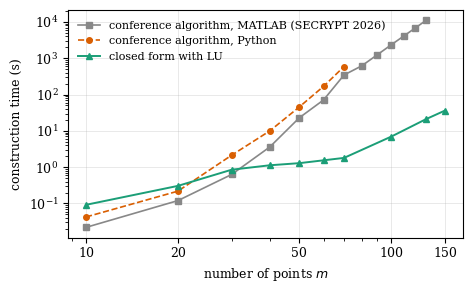

In [6]:
# Formatting helpers, shared by the inline tables (tex=False) and the LaTeX tables of Section 12.
def fmt_sci(x, tex=False, digits=1):
    if x == 0:
        return "$0$" if tex else "0"
    e = int(math.floor(math.log10(abs(x))))
    mant = x / 10 ** e
    if round(mant, digits) >= 10:
        mant /= 10
        e += 1
    return f"${mant:.{digits}f}\\times10^{{{e}}}$" if tex else f"{mant:.{digits}f}e{e}"


def secs(x, tex=False):
    if x < 0.001:
        return "$<0.001$" if tex else "<0.001"
    if x < 0.1:
        return f"{x:.3f}"
    if x < 10:
        return f"{x:.2f}"
    if x < 100:
        return f"{x:.1f}"
    return f"{x:,.0f}".replace(",", "{,}" if tex else ",")


def given(x, tex=False):
    """A number as the conference paper printed it."""
    return f"{int(x):,}".replace(",", "{,}" if tex else ",") if x >= 1000 else f"{x:g}"


def big_int(n, tex=False):
    return f"{n:,}".replace(",", "{,}" if tex else ",") if n >= 10000 else f"{n}"


def table1_rows(x1, tex=False):
    acc = defaultdict(list)
    for r in x1["accuracy"]:
        acc[(r["mode"], r["m"])].append(r)
    rows = []
    for m in sorted({r["m"] for r in x1["accuracy"]}):
        u, c = acc[("unclipped", m)], acc[("constant", m)]
        n_pairs = sum(r["h"] for r in u)
        rows.append([m, u[0]["h"], fmt_sci(np.median([r["condV"] for r in u + c]), tex),
                     f"{sum(r['conf_imag'] for r in u)}/{n_pairs}", fmt_sci(max(r["conf_relerr_max"] for r in u), tex),
                     f"{sum(r['conf_imag'] for r in c)}/{n_pairs}", fmt_sci(max(r["conf_relerr_max"] for r in c), tex),
                     fmt_sci(max(r["stable_relerr_max"] for r in u + c), tex)])
    return rows


def table2_rows(x1, tex=False):
    conf = x1["conference_matlab_seconds"]
    tc = {r["m"]: r for r in x1["time_conference_algorithm"]}
    tl = {r["m"]: r for r in x1["time_closed_form"]}
    rows = []
    for m in sorted(set(tc) | set(tl)):
        row = [m, big_int(m * (m - 1) // 2, tex), given(conf[str(m)], tex) if str(m) in conf else "--",
               secs(tc[m]["lift"] + tc[m]["conference"], tex) if m in tc else "--"]
        if m in tl:
            row += [secs(tl[m]["build"], tex), secs(1000 * tl[m]["query"], tex), fmt_sci(tl[m]["relerr_max"], tex)]
        else:
            row += ["--", "--", "--"]
        rows.append(row)
    return rows


def figure1(x1, path=None):
    conf = {int(k): v for k, v in x1["conference_matlab_seconds"].items()}
    py = {r["m"]: r["lift"] + r["conference"] for r in x1["time_conference_algorithm"]}
    lu = {r["m"]: r["build"] for r in x1["time_closed_form"]}
    plt.rcParams.update({"font.size": 9, "font.family": "serif"})
    fig, ax = plt.subplots(figsize=(4.8, 3.0))
    ax.loglog(sorted(conf), [conf[m] for m in sorted(conf)], "s-", color="#888888", ms=4, lw=1.2,
              label="conference algorithm, MATLAB (SECRYPT 2026)")
    ax.loglog(sorted(py), [py[m] for m in sorted(py)], "o--", color="#d95f02", ms=4, lw=1.2,
              label="conference algorithm, Python")
    ax.loglog(sorted(lu), [lu[m] for m in sorted(lu)], "^-", color="#1b9e77", ms=4, lw=1.4,
              label="closed form with LU")
    ax.set_xlabel("number of points $m$")
    ax.set_ylabel("construction time (s)")
    ax.set_xticks([10, 20, 50, 100, 150])
    ax.set_xticklabels(["10", "20", "50", "100", "150"])
    ax.grid(True, which="major", lw=0.4, alpha=0.5)
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    fig.tight_layout()
    if path is not None:
        fig.savefig(path, dpi=200)
    return fig


show_table("Table 1. Accuracy on the data pairs (synthetic data, two seeds per m, eps = d_min/10). "
           "'complex' counts pairs with v'Av < 0. 'rel. err.' is the largest relative error over the real values.",
           ["m", "h", "κ(V)", "unclipped: complex", "unclipped: rel. err.", "constant: complex",
            "constant: rel. err.", "closed form: rel. err."], table1_rows(x1))
show_table("Table 2. Construction time in seconds (synthetic data in R², three clusters). The MATLAB column "
           "repeats Table 1 of the conference paper. 'query' evaluates one new pair.",
           ["m", "h", "conference, MATLAB", "conference, Python", "closed form: build (s)", "query (ms)", "rel. err."],
           table2_rows(x1))
figure1(x1, RESULTS / "fig1_time.png")
plt.show()

## 6. Experiment X2: attacks on clustering algorithms (Sect. 5, Tables 3 and 4)

Synthetic data as in the conference benchmarks, constant targets, ε = d_min/10, double precision.

(a) The three conference algorithms. K-means follows the conference protocol: the desired centres are
extra data points, and one assignment step to these centres gives the clusters. DBSCAN uses MinPts = 2
and a radius halfway between the two target levels. Agglomerative clustering uses average linkage and
cuts at three clusters.

(b) For m ≥ 30, eight library implementations run on the realised dissimilarity matrix with their
default hyperparameters, except the number of clusters and the DBSCAN radius.

In [7]:
import warnings

# The k-nearest-neighbour graph of spectral clustering falls apart into the desired clusters. That is
# the point of the attack, so scikit-learn's warning about a disconnected graph is expected.
warnings.filterwarnings("ignore", message="Graph is not fully connected")

X2_M = (10, 20, 30, 50) if QUICK else (10, 20, 30, 50, 70, 100, 130)
X2_SEEDS = (0, 1) if QUICK else (0, 1, 2)


def run_x2():
    rows, lib = [], []
    for m in X2_M:
        for seed in X2_SEEDS:
            Y, lab = synthetic(m, 1000 * m + seed, min_size=5 if m >= 30 else 2)
            T, delta, d_min = two_level_targets(Y, lab, mode="constant")
            s_lo, D = delta.min(), delta.max()
            t0 = time.perf_counter()
            E = EpsSemimetric(Y, delta, d_min / 10)
            t_build = time.perf_counter() - t0
            t0 = time.perf_counter()
            R = square(m, E.on_data())
            t_eval = time.perf_counter() - t0
            off = ~np.eye(m, dtype=bool)
            relerr = float(np.max(np.abs(R - T)[off] / T[off]))
            tau = triangle_defect(R)
            out = {}
            t0 = time.perf_counter()
            km = np.argmin(R[:, :3], axis=1) + 1            # one assignment step to the three centres
            out["kmeans"] = (adjusted_rand_score(lab, km), time.perf_counter() - t0)
            t0 = time.perf_counter()
            db = DBSCAN(eps=0.5 * (s_lo + D), min_samples=2, metric="precomputed").fit_predict(R)
            out["dbscan"] = (adjusted_rand_score(lab, db), time.perf_counter() - t0)
            t0 = time.perf_counter()
            ag = fcluster(linkage(squareform(R, checks=False), "average"), 3, criterion="maxclust")
            out["average"] = (adjusted_rand_score(lab, ag), time.perf_counter() - t0)
            rows.append(dict(m=m, seed=seed, h=E.h, build=t_build, eval_data=t_eval, relerr_max=relerr,
                             tau_over_eps=tau / E.eps, noise_dbscan=int((db == -1).sum()),
                             **{f"ari_{k}": v[0] for k, v in out.items()}, **{f"t_{k}": v[1] for k, v in out.items()}))
            line = (f"m={m:3d} seed={seed}: build+eval {t_build + t_eval:.2f} s, rel. err. {relerr:.1e}, "
                    f"tau {tau / E.eps:+.3f} eps, ARI K-means {out['kmeans'][0]:.3f} DBSCAN {out['dbscan'][0]:.3f} "
                    f"average {out['average'][0]:.3f}")
            if m >= 30:
                algs = {
                    "DBSCAN": lambda: DBSCAN(eps=0.5 * (s_lo + D), metric="precomputed").fit_predict(R),
                    "HDBSCAN": lambda: HDBSCAN(metric="precomputed", copy=True).fit_predict(R),
                    "OPTICS": lambda: OPTICS(metric="precomputed").fit_predict(R),
                    "single": lambda: AgglomerativeClustering(3, metric="precomputed", linkage="single").fit_predict(R),
                    "complete": lambda: AgglomerativeClustering(3, metric="precomputed", linkage="complete").fit_predict(R),
                    "average": lambda: AgglomerativeClustering(3, metric="precomputed", linkage="average").fit_predict(R),
                    "kmedoids": lambda: np.asarray(kmedoids.fasterpam(R, 3, init="build", random_state=0, n_cpu=1).labels),
                    "spectral": lambda: SpectralClustering(3, affinity="precomputed_nearest_neighbors",
                                                           random_state=0).fit_predict(R),
                }
                for name, f in algs.items():
                    t0 = time.perf_counter()
                    pred = f()
                    lib.append(dict(m=m, seed=seed, alg=name, ari=float(adjusted_rand_score(lab, pred)),
                                    noise=int((pred == -1).sum()), seconds=time.perf_counter() - t0))
                line += f", library min. ARI {min(r['ari'] for r in lib[-len(algs):]):.3f}"
            print(line)
            del E
    return dict(conference=rows, library=lib)


x2 = run_or_load("x2.json", run_x2)

m= 10 seed=0: build+eval 0.03 s, rel. err. 1.6e-14, tau -0.050 eps, ARI K-means 1.000 DBSCAN 1.000 average 1.000
m= 10 seed=1: build+eval 0.02 s, rel. err. 3.6e-15, tau -0.050 eps, ARI K-means 1.000 DBSCAN 1.000 average 1.000
m= 10 seed=2: build+eval 0.03 s, rel. err. 2.3e-15, tau -0.050 eps, ARI K-means 1.000 DBSCAN 1.000 average 1.000
m= 20 seed=0: build+eval 0.12 s, rel. err. 4.6e-15, tau -0.050 eps, ARI K-means 1.000 DBSCAN 1.000 average 1.000
m= 20 seed=1: build+eval 0.12 s, rel. err. 2.1e-14, tau -0.050 eps, ARI K-means 1.000 DBSCAN 1.000 average 1.000
m= 20 seed=2: build+eval 0.12 s, rel. err. 2.4e-14, tau -0.050 eps, ARI K-means 1.000 DBSCAN 1.000 average 1.000
m= 30 seed=0: build+eval 0.32 s, rel. err. 1.0e-14, tau -0.050 eps, ARI K-means 1.000 DBSCAN 1.000 average 1.000, library min. ARI 1.000
m= 30 seed=1: build+eval 0.30 s, rel. err. 1.2e-13, tau -0.050 eps, ARI K-means 1.000 DBSCAN 1.000 average 1.000, library min. ARI 1.000
m= 30 seed=2: build+eval 0.25 s, rel. err. 7.5e-

m= 30 seed=1: build+eval 0.17 s, rel. err. 9.6e-14, tau -0.050 eps, ARI K-means 1.000 DBSCAN 1.000 average 1.000, library min. ARI 1.000
m= 30 seed=2: build+eval 0.13 s, rel. err. 3.3e-14, tau -0.050 eps, ARI K-means 1.000 DBSCAN 1.000 average 1.000, library min. ARI 1.000


m= 50 seed=0: build+eval 0.50 s, rel. err. 8.4e-14, tau -0.050 eps, ARI K-means 1.000 DBSCAN 1.000 average 1.000, library min. ARI 1.000


m= 50 seed=1: build+eval 0.53 s, rel. err. 2.9e-14, tau -0.050 eps, ARI K-means 1.000 DBSCAN 1.000 average 1.000, library min. ARI 1.000


m= 50 seed=2: build+eval 0.46 s, rel. err. 8.1e-14, tau -0.050 eps, ARI K-means 1.000 DBSCAN 1.000 average 1.000, library min. ARI 1.000


m= 70 seed=0: build+eval 1.62 s, rel. err. 9.7e-13, tau -0.050 eps, ARI K-means 1.000 DBSCAN 1.000 average 1.000, library min. ARI 1.000


... (4 outputs left out)

m=100 seed=2: build+eval 7.10 s, rel. err. 3.7e-13, tau -0.050 eps, ARI K-means 1.000 DBSCAN 1.000 average 1.000, library min. ARI 1.000


m=130 seed=0: build+eval 26.92 s, rel. err. 3.6e-13, tau -0.050 eps, ARI K-means 1.000 DBSCAN 1.000 average 1.000, library min. ARI 1.000


m=130 seed=1: build+eval 28.07 s, rel. err. 3.9e-13, tau -0.050 eps, ARI K-means 1.000 DBSCAN 1.000 average 1.000, library min. ARI 1.000


m=130 seed=2: build+eval 27.15 s, rel. err. 1.8e-12, tau -0.050 eps, ARI K-means 1.000 DBSCAN 1.000 average 1.000, library min. ARI 1.000
saved results/x2.json after 112 s


In [8]:
LIB_NAMES = {"DBSCAN": "DBSCAN", "HDBSCAN": "HDBSCAN", "OPTICS": "OPTICS", "single": "single linkage",
             "complete": "complete linkage", "average": "average linkage", "kmedoids": "k-medoids (FasterPAM)",
             "spectral": "spectral (kNN graph)"}
LIB_HYPER_TEX = {"DBSCAN": "$r=(s_0+D)/2$, $\\mathit{MinPts}=5$", "HDBSCAN": "min.\\ cluster size $5$",
                 "OPTICS": "$\\mathit{MinPts}=5$, $\\xi=0.05$", "single": "$3$ clusters", "complete": "$3$ clusters",
                 "average": "$3$ clusters", "kmedoids": "$k=3$, BUILD", "spectral": "$k=3$, $10$ neighbours"}
LIB_HYPER = {"DBSCAN": "r = (s0 + D)/2, MinPts = 5", "HDBSCAN": "min. cluster size 5", "OPTICS": "MinPts = 5, xi = 0.05",
             "single": "3 clusters", "complete": "3 clusters", "average": "3 clusters", "kmedoids": "k = 3, BUILD",
             "spectral": "k = 3, 10 neighbours"}


def table3_rows(x2, tex=False):
    by = defaultdict(list)
    for r in x2["conference"]:
        by[r["m"]].append(r)
    rows = []
    for m in sorted(by):
        rs = by[m]
        tau = f"{max(r['tau_over_eps'] for r in rs):.2f}"
        rows.append([m, rs[0]["h"], secs(np.mean([r["build"] + r["eval_data"] for r in rs]), tex),
                     fmt_sci(max(r["relerr_max"] for r in rs), tex), f"${tau}$" if tex else tau,
                     f"{min(r['ari_kmeans'] for r in rs):.3f}", f"{min(r['ari_dbscan'] for r in rs):.3f}",
                     f"{min(r['ari_average'] for r in rs):.3f}"])
    return rows


def table4_rows(x2, tex=False):
    lib = defaultdict(list)
    for r in x2["library"]:
        lib[r["alg"]].append(r)
    rows = []
    for a in LIB_NAMES:
        rs = lib[a]
        if not rs:
            continue
        name = LIB_NAMES[a].replace("k-medoids", "$k$-medoids").replace("kNN", "$k$NN") if tex else LIB_NAMES[a]
        rows.append([name, LIB_HYPER_TEX[a] if tex else LIB_HYPER[a], len(rs), f"{min(r['ari'] for r in rs):.3f}",
                     sum(r["noise"] for r in rs), secs(np.mean([r["seconds"] for r in rs]), tex)])
    return rows


show_table("Table 3. The three conference algorithms under the eps-semimetric. 'time' covers the construction "
           "and the evaluation of all data pairs (mean over seeds). The last three columns give the smallest ARI.",
           ["m", "h", "time (s)", "rel. err.", "τ/ε", "K-means", "DBSCAN", "average linkage"], table3_rows(x2))
show_table(f"Table 4. Library implementations on the realised dissimilarity, m in "
           f"{sorted({r['m'] for r in x2['library']})}. 'noise' counts points labelled as noise over all runs.",
           ["algorithm", "hyperparameters", "runs", "min. ARI", "noise", "time (s)"], table4_rows(x2))

**Table 3. The three conference algorithms under the eps-semimetric. 'time' covers the construction and the evaluation of all data pairs (mean over seeds). The last three columns give the smallest ARI.**

| m | h | time (s) | rel. err. | τ/ε | K-means | DBSCAN | average linkage |
|---|---|---|---|---|---|---|---|
| 10 | 45 | 0.027 | 1.6e-14 | -0.05 | 1.000 | 1.000 | 1.000 |
| 20 | 190 | 0.12 | 2.4e-14 | -0.05 | 1.000 | 1.000 | 1.000 |
| 30 | 435 | 0.29 | 1.2e-13 | -0.05 | 1.000 | 1.000 | 1.000 |
| 50 | 1225 | 0.75 | 1.5e-13 | -0.05 | 1.000 | 1.000 | 1.000 |
| 70 | 2415 | 2.31 | 1.1e-12 | -0.05 | 1.000 | 1.000 | 1.000 |
| 100 | 4950 | 13.9 | 4.4e-13 | -0.05 | 1.000 | 1.000 | 1.000 |
| 130 | 8385 | 35.3 | 1.2e-11 | -0.05 | 1.000 | 1.000 | 1.000 |

**Table 4. Library implementations on the realised dissimilarity, m in [30, 50, 70, 100, 130]. 'noise' counts points labelled as noise over all runs.**

| algorithm | hyperparameters | runs | min. ARI | noise | time (s) |
|---|---|---|---|---|---|
| DBSCAN | r = (s0 + D)/2, MinPts = 5 | 15 | 1.000 | 0 | 0.004 |
| HDBSCAN | min. cluster size 5 | 15 | 1.000 | 0 | 0.005 |
| OPTICS | MinPts = 5, xi = 0.05 | 15 | 1.000 | 0 | 0.093 |
| single linkage | 3 clusters | 15 | 1.000 | 0 | 0.003 |
| complete linkage | 3 clusters | 15 | 1.000 | 0 | 0.003 |
| average linkage | 3 clusters | 15 | 1.000 | 0 | 0.003 |
| k-medoids (FasterPAM) | k = 3, BUILD | 15 | 1.000 | 0 | 0.002 |
| spectral (kNN graph) | k = 3, 10 neighbours | 15 | 1.000 | 0 | 0.063 |

## 7. Experiment X3: fairness impact on real data (Sect. 6, Tables 5 and 6)

(a) The Adult experiment of the conference paper (ten records, protected attribute race), rerun with
the constant targets. The baseline is K-means with the Euclidean distance. The attack follows the
conference K-means protocol.

(b) Five samples of m = 100 individuals with distinct feature vectors from each dataset. The decision
pipeline is k-medoids (FasterPAM, k = 2), and both attacks of Section 4 change only the dissimilarity.
k-medoids, average linkage and DBSCAN then run on the ε-semimetric of each attack.

In [9]:
X3_M = 60 if QUICK else 100          # individuals per sample
X3_SEEDS = range(2) if QUICK else range(5)


def attack(X, part, eps_div=10):
    """Construct the eps-semimetric for a target partition and run three algorithms on it."""
    T, delta, d_min = two_level_targets(X, part, mode="constant")
    t0 = time.perf_counter()
    E = EpsSemimetric(X, delta, d_min / eps_div)
    R = square(len(X), E.on_data())
    t = time.perf_counter() - t0
    off = ~np.eye(len(X), dtype=bool)
    out = dict(seconds=t, tau_over_eps=triangle_defect(R) / E.eps, eps=E.eps,
               relerr_max=float(np.max(np.abs(R - T)[off] / T[off])))
    lab_km, _ = kmed(R)
    lab_av = fcluster(linkage(squareform(R, checks=False), "average"), 2, criterion="maxclust")
    lab_db = DBSCAN(eps=0.5 * (delta.min() + delta.max()), min_samples=2, metric="precomputed").fit_predict(R)
    out.update(ari_kmedoids=adjusted_rand_score(part, lab_km), ari_average=adjusted_rand_score(part, lab_av),
               ari_dbscan=adjusted_rand_score(part, lab_db))
    return out, lab_km


def run_x3():
    res = {}
    # (a) the Adult experiment of the conference paper
    ad = adult_conference()
    y, y_aug, lab_aug, white, high = ad["y"], ad["y_aug"], ad["labels_aug"], ad["white"], ad["high"]
    black = 1 - white
    base = KMeans(2, n_init=20, random_state=0).fit_predict(y)
    F = int(np.argmax([high[base == c].mean() for c in (0, 1)]))
    fav_base = (base == F).astype(int)
    T_clip, _, d_min = two_level_targets(y_aug, lab_aug, mode="clipped")
    T_c, delta, _ = two_level_targets(y_aug, lab_aug, mode="constant")
    eps = d_min / 10
    t0 = time.perf_counter()
    E = EpsSemimetric(y_aug, delta, eps)
    R = square(len(y_aug), E.on_data())
    t_build = time.perf_counter() - t0
    assign = np.argmin(R[2:, :2], axis=1) + 1                # one K-means assignment step to the two centres
    fav_adv = (assign == 1).astype(int)                      # centre 1 = White = favourable
    res["adult_conference"] = dict(
        p_white_base=float(fav_base[white == 1].mean()), p_black_base=float(fav_base[black == 1].mean()),
        dpd_base=float(dpd(fav_base, black)),
        p_white_adv=float(fav_adv[white == 1].mean()), p_black_adv=float(fav_adv[black == 1].mean()),
        dpd_adv=float(dpd(fav_adv, black)), accuracy=float((assign == lab_aug[2:]).mean()),
        eps=eps, seconds=t_build, tau_clipped_over_eps=triangle_defect(T_clip) / eps,
        tau_constant_over_eps=triangle_defect(T_c) / eps, D=float(delta.max()), small=float(delta.min()),
        d_own_max=float(np.max([R[2 + i, lab_aug[2 + i] - 1] for i in range(10)])),
        d_other_min=float(np.min([R[2 + i, 2 - lab_aug[2 + i]] for i in range(10)])))
    a = res["adult_conference"]
    print(f"Adult, ten records: DPD {a['dpd_base']:.3f} (baseline) -> {a['dpd_adv']:.3f} (attack), "
          f"accuracy {100 * a['accuracy']:.0f}%, construction {a['seconds']:.3f} s")

    # (b) samples from three datasets
    rows = []
    for name in DATASETS:
        d = load_dataset(name)
        for seed in X3_SEEDS:
            X, a_, ylab = sample_distinct(d, X3_M, seed)
            fav, part_t, part_m, info = honest_and_attacks(X, a_, ylab, seed)
            row = dict(dataset=name, seed=seed, m=X3_M, **info)
            for tag, part in (("targeted", part_t), ("maximal", part_m)):
                out, lab_att = attack(X, part)
                cl = np.unique(lab_att)
                Fa = cl[int(np.argmax([ylab[lab_att == c].mean() for c in cl]))]
                fav_a = (lab_att == Fa).astype(int)
                row.update({f"{tag}_{k}": v for k, v in out.items()})
                row.update({f"{tag}_dpd": dpd(fav_a, a_), f"{tag}_di": di(fav_a, a_), f"{tag}_eod": eod(fav_a, a_, ylab),
                            f"{tag}_changed": int((fav_a != fav).sum()),
                            f"{tag}_changed_nonprotected": int(((fav_a != fav) & (a_ == 0)).sum())})
            rows.append(row)
            print(f"{name:13s} sample {seed}: n_p = {row['n_protected']:3d}, honest DPD {row['dpd']:+.3f} "
                  f"[{row['dpd_lo']:+.3f}, {row['dpd_hi']:+.3f}], targeted g = {row['g']:2d} -> DPD "
                  f"{row['targeted_dpd']:+.3f}, maximal DPD {row['maximal_dpd']:+.3f}, ARI "
                  f"{min(row[f'{t}_ari_{k}'] for t in ('targeted', 'maximal') for k in ('kmedoids', 'average', 'dbscan')):.3f}")
    res["samples"] = rows
    return res


x3 = run_or_load("x3.json", run_x3)

Adult, ten records: DPD 0.200 (baseline) -> 1.000 (attack), accuracy 100%, construction 0.066 s
Adult         sample 0: n_p =   8, honest DPD +0.185 [-0.198, +0.474], targeted g =  2 -> DPD +0.435, maximal DPD +1.000, ARI 1.000
Adult         sample 1: n_p =  17, honest DPD -0.009 [-0.265, +0.244], targeted g =  4 -> DPD +0.227, maximal DPD +1.000, ARI 1.000
Adult         sample 2: n_p =   9, honest DPD +0.263 [-0.025, +0.451], targeted g =  1 -> DPD +0.374, maximal DPD +1.000, ARI 1.000
Adult         sample 3: n_p =  18, honest DPD +0.107 [-0.124, +0.319], targeted g =  3 -> DPD +0.274, maximal DPD +1.000, ARI 1.000
Adult         sample 4: n_p =  13, honest DPD -0.005 [-0.309, +0.299], targeted g =  3 -> DPD +0.225, maximal DPD +1.000, ARI 1.000
COMPAS        sample 0: n_p =  51, honest DPD +0.054 [-0.123, +0.245], targeted g =  9 -> DPD +0.231, maximal DPD +1.000, ARI 1.000
COMPAS        sample 1: n_p =  58, honest DPD -0.054 [-0.259, +0.151], targeted g = 11 -> DPD +0.135, maximal DP

Adult         sample 2: n_p =   9, honest DPD +0.263 [-0.025, +0.451], targeted g =  1 -> DPD +0.374, maximal DPD +1.000, ARI 1.000


Adult         sample 3: n_p =  18, honest DPD +0.107 [-0.124, +0.319], targeted g =  3 -> DPD +0.274, maximal DPD +1.000, ARI 1.000


Adult         sample 4: n_p =  13, honest DPD -0.005 [-0.309, +0.299], targeted g =  3 -> DPD +0.225, maximal DPD +1.000, ARI 1.000


COMPAS        sample 0: n_p =  51, honest DPD +0.054 [-0.123, +0.245], targeted g =  9 -> DPD +0.231, maximal DPD +1.000, ARI 1.000


COMPAS        sample 1: n_p =  58, honest DPD -0.054 [-0.259, +0.151], targeted g = 11 -> DPD +0.135, maximal DPD +1.000, ARI 1.000


... (4 outputs left out)

German Credit sample 1: n_p =  31, honest DPD -0.081 [-0.293, +0.136], targeted g =  6 -> DPD +0.112, maximal DPD +1.000, ARI 1.000


German Credit sample 2: n_p =  32, honest DPD -0.011 [-0.226, +0.199], targeted g =  6 -> DPD +0.176, maximal DPD +1.000, ARI 1.000


German Credit sample 3: n_p =  31, honest DPD +0.030 [-0.172, +0.234], targeted g =  6 -> DPD +0.223, maximal DPD +1.000, ARI 1.000


German Credit sample 4: n_p =  28, honest DPD +0.105 [-0.115, +0.323], targeted g =  6 -> DPD +0.319, maximal DPD +1.000, ARI 1.000
saved results/x3.json after 242 s


In [10]:
def table5_rows(x3, tex=False):
    a = x3["adult_conference"]
    m = (lambda s: f"${s}$") if tex else (lambda s: s)
    pct = "\\%" if tex else "%"
    unit = "\\,s" if tex else " s"
    labels = ([r"$P(\text{fav}\mid\text{White})$", r"$P(\text{fav}\mid\text{Black})$", "DPD", "Attack accuracy",
               "Construction time", r"Triangle defect $\tau/\eps$ of the targets"] if tex else
              ["P(fav | White)", "P(fav | Black)", "DPD", "attack accuracy", "construction time",
               "triangle defect τ/ε of the targets"])
    values = [
        [m("0.400"), m("1.000"), m(f"{a['p_white_base']:.3f}"), m(f"{a['p_white_adv']:.3f}")],
        [m("0.200"), m("0.000"), m(f"{a['p_black_base']:.3f}"), m(f"{a['p_black_adv']:.3f}")],
        [m("0.200"), m("1.000"), m(f"{a['dpd_base']:.3f}"), m(f"{a['dpd_adv']:.3f}")],
        ["--", m("100" + pct), "--", m(f"{100 * a['accuracy']:.0f}" + pct)],
        ["--", m("0.026") + unit, "--", m(f"{a['seconds']:.3f}") + unit],
        ["--", m(f"{a['tau_clipped_over_eps']:.1f}"), "--", m(f"{a['tau_constant_over_eps']:.2f}")],
    ]
    return [[label] + v for label, v in zip(labels, values)]


def table6_rows(x3, tex=False):
    S = x3["samples"]
    m = (lambda s: f"${s}$") if tex else (lambda s: s)
    rows = []
    for name in DATASETS:
        rs = [r for r in S if r["dataset"] == name]
        if not rs:
            continue
        mean = lambda k: np.mean([r[k] for r in rs])
        g_lo, g_hi = min(r["g"] for r in rs), max(r["g"] for r in rs)
        g = f"{g_lo}" if g_lo == g_hi else (f"{g_lo}--{g_hi}" if tex else f"{g_lo}-{g_hi}")
        half = np.mean([(r["dpd_hi"] - r["dpd_lo"]) / 2 for r in rs])
        honest = m(f"{mean('dpd'):.3f}\\pm{half:.3f}") if tex else f"{mean('dpd'):.3f} ± {half:.3f}"
        inside = sum(r["dpd_lo"] <= r["targeted_dpd"] <= r["dpd_hi"] for r in rs)
        rows.append([name, f"{mean('n_protected'):.1f}", honest, m(f"{mean('di'):.2f}"), g,
                     m(f"{mean('targeted_dpd'):.3f}"), m(f"{mean('targeted_di'):.2f}"), f"{inside}/{len(rs)}",
                     m(f"{mean('maximal_dpd'):.3f}")])
    return rows


show_table("Table 5. The Adult experiment of the conference paper (ten individuals, protected attribute race). "
           "The conference columns repeat Table 6 of the conference paper, except for the triangle defect.",
           ["", "conference: baseline", "conference: attack", "this version: baseline", "this version: attack"],
           table5_rows(x3))
show_table(f"Table 6. Attacks on samples of m = {X3_M} individuals (means over the samples of each dataset). "
           "The honest DPD carries the mean half-width of its 95% bootstrap interval. 'in CI' counts the samples "
           "whose attacked DPD lies inside the honest interval.",
           ["dataset", "n_p", "honest DPD", "honest DI", "g", "targeted DPD", "targeted DI", "in CI", "maximal DPD"],
           table6_rows(x3))
_S = x3["samples"]
print("smallest ARI over all attacks and algorithms:",
      f"{min(r[f'{t}_ari_{k}'] for r in _S for t in ('targeted', 'maximal') for k in ('kmedoids', 'average', 'dbscan')):.3f}",
      "| largest DI under the maximal attack:", f"{max(r['maximal_di'] for r in _S):.2f}",
      "| decisions of non-protected individuals changed by the targeted attack:",
      sum(r["targeted_changed_nonprotected"] for r in _S))

**Table 5. The Adult experiment of the conference paper (ten individuals, protected attribute race). The conference columns repeat Table 6 of the conference paper, except for the triangle defect.**

|  | conference: baseline | conference: attack | this version: baseline | this version: attack |
|---|---|---|---|---|
| P(fav | White) | 0.400 | 1.000 | 0.400 | 1.000 |
| P(fav | Black) | 0.200 | 0.000 | 0.200 | 0.000 |
| DPD | 0.200 | 1.000 | 0.200 | 1.000 |
| attack accuracy | -- | 100% | -- | 100% |
| construction time | -- | 0.026 s | -- | 0.066 s |
| triangle defect τ/ε of the targets | -- | 91.4 | -- | -0.05 |

**Table 6. Attacks on samples of m = 100 individuals (means over the samples of each dataset). The honest DPD carries the mean half-width of its 95% bootstrap interval. 'in CI' counts the samples whose attacked DPD lies inside the honest interval.**

| dataset | n_p | honest DPD | honest DI | g | targeted DPD | targeted DI | in CI | maximal DPD |
|---|---|---|---|---|---|---|---|---|
| Adult | 13.0 | 0.108 ± 0.271 | 0.71 | 1-4 | 0.307 | 0.24 | 5/5 | 1.000 |
| COMPAS | 57.0 | 0.074 ± 0.193 | 0.85 | 9-12 | 0.256 | 0.45 | 5/5 | 1.000 |
| German Credit | 28.8 | -0.003 ± 0.217 | 1.01 | 5-6 | 0.200 | 0.60 | 5/5 | 0.990 |

smallest ARI over all attacks and algorithms: 1.000 | largest DI under the maximal attack: 0.00 | decisions of non-protected individuals changed by the targeted attack: 0


## 8. Experiment X4: the statistical tests of the conference paper (Sect. 7.2, Table 7)

The auditor queries the dissimilarity and knows the standardised features.

* *Triangle test on data triples:* the largest defect d(x, y) − d(x, z) − d(z, y) over triples of data points.
* *Triangle test with fresh points:* the same over triples with one fresh point, drawn uniformly from the
  bounding box of the sample, and two data points, in both positions of the fresh point.
* *Embedding test:* Kruskal's stress-1 of a classical MDS embedding of the data into ℝ^ℓ.

Defects are relative to the largest data distance. As in the conference paper, a test flags a relative
defect above 10⁻⁶ or a stress above 0.2. The tests run on six legitimate dissimilarities and on the
ε-semimetric of the targeted attack (all samples) and of the maximal attack (first sample per dataset).
A last part repeats the targeted attack with ε = d_min/10, d_min/100 and d_min/1000 (Proposition 2) and
records the estimated condition number of V.

In [11]:
N_FRESH = 40
X4_SEEDS = range(2) if QUICK else range(5)


def tri_data(D):
    return triangle_defect(D)


def tri_fresh(D, DP):
    """DP[p, i] = d(p, y_i). Largest defect over the triples (y_i, p, y_j) and (p, y_i, y_j)."""
    best = -np.inf
    off = ~np.eye(len(D), dtype=bool)
    for dp in DP:
        A1 = D - dp[:, None] - dp[None, :]          # d(y_i, y_j) - d(y_i, p) - d(p, y_j)
        A2 = dp[:, None] - D - dp[None, :]          # d(p, y_i) - d(y_i, y_j) - d(y_j, p)
        best = max(best, float(A1[off].max()), float(A2[off].max()))
    return best


def stress(D, ell):
    """Kruskal stress-1 of a classical MDS embedding into R^ell."""
    n = len(D)
    J = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * J @ (D ** 2) @ J
    w, U = np.linalg.eigh(B)
    idx = np.argsort(w)[::-1][:ell]
    Z = U[:, idx] * np.sqrt(np.maximum(w[idx], 0.0))
    Dh = cdist(Z, Z)
    iu = np.triu_indices(n, 1)
    return float(np.sqrt(((D[iu] - Dh[iu]) ** 2).sum() / (D[iu] ** 2).sum()))


def benign(X, P, seed):
    r = np.random.default_rng(100 + seed)
    w = np.exp(r.uniform(np.log(1 / 3), np.log(3), X.shape[1]))     # feature weights in [1/3, 3]
    VI = np.linalg.inv(np.cov(X, rowvar=False))
    out = {}
    for name, kw in (("Euclidean", dict(metric="euclidean")), ("Manhattan", dict(metric="cityblock")),
                     ("Chebyshev", dict(metric="chebyshev")), ("Mahalanobis", dict(metric="mahalanobis", VI=VI)),
                     ("weighted Euclidean", dict(metric="seuclidean", V=1 / w)), ("cosine", dict(metric="cosine"))):
        out[name] = (cdist(X, X, **kw), cdist(P, X, **kw))
    return out


def attack_dists(X, part, P, eps_div=10):
    _, delta, d_min = two_level_targets(X, part, mode="constant")
    E = EpsSemimetric(X, delta, d_min / eps_div)
    D = square(len(X), E.on_data())
    DP = np.vstack([E.dists_lifted(np.column_stack([lift(p, X[i], E.s, E.h) for i in range(len(X))])) for p in P])
    return D, DP, E.eps, E.cond1_estimate()


def test_stats(D, DP, ell):
    scale = float(D.max())                           # largest data distance
    return dict(tri_data=tri_data(D) / scale, tri_fresh=tri_fresh(D, DP) / scale, stress=stress(D, ell), scale=scale)


def run_x4():
    rows, sweep = [], []
    for name in DATASETS:
        d = load_dataset(name)
        for seed in X4_SEEDS:
            X, a, ylab = sample_distinct(d, X3_M, seed)
            fav, part_t, part_m, info = honest_and_attacks(X, a, ylab, seed)
            P = np.random.default_rng(200 + seed).uniform(X.min(0), X.max(0), size=(N_FRESH, X.shape[1]))
            for metric, (D, DP) in benign(X, P, seed).items():
                rows.append(dict(dataset=name, seed=seed, metric=metric, **test_stats(D, DP, X.shape[1])))
            attacks = [("attack, targeted", part_t)] + ([("attack, maximal", part_m)] if seed == 0 else [])
            for tag, part in attacks:
                D, DP, eps, _ = attack_dists(X, part, P)
                st = test_stats(D, DP, X.shape[1])
                st["tri_fresh_over_eps"] = st["tri_fresh"] * st["scale"] / eps
                st["tri_data_over_eps"] = st["tri_data"] * st["scale"] / eps
                rows.append(dict(dataset=name, seed=seed, metric=tag, eps=eps, **st))
            att = [r for r in rows if r["dataset"] == name and r["seed"] == seed and r["metric"].startswith("attack")]
            print(f"{name:13s} sample {seed}: attacks: relative defect on data triples "
                  f"{max(r['tri_data'] for r in att):+.4f}, with fresh points {min(r['tri_fresh'] for r in att):.0f}, "
                  f"stress {max(r['stress'] for r in att):.3f}")
            if seed == 0:
                for div in (10, 100, 1000):
                    D, DP, eps, cond = attack_dists(X, part_t, P, eps_div=div)
                    sweep.append(dict(dataset=name, eps=eps, tri_data=tri_data(D), tri_fresh=tri_fresh(D, DP),
                                      max_target=float(D.max()), cond1_V=cond))
                    print(f"   eps = d_min/{div}: defect with fresh points {sweep[-1]['tri_fresh']:.12f}, "
                          f"condition number of V {cond:.2e}")
    return dict(rows=rows, eps_sweep=sweep)


x4 = run_or_load("x4.json", run_x4)

Adult         sample 0: attacks: relative defect on data triples -0.0051, with fresh points 148, stress 0.011
   eps = d_min/10: defect with fresh points 19.619710535828, condition number of V 1.23e+08
   eps = d_min/100: defect with fresh points 19.619710535864, condition number of V 1.22e+09
   eps = d_min/1000: defect with fresh points 19.619710535839, condition number of V 1.21e+10
Adult         sample 1: attacks: relative defect on data triples -0.0051, with fresh points 1275, stress 0.005
Adult         sample 2: attacks: relative defect on data triples -0.0009, with fresh points 4566, stress 0.001
Adult         sample 3: attacks: relative defect on data triples -0.0051, with fresh points 744, stress 0.005
Adult         sample 4: attacks: relative defect on data triples -0.0025, with fresh points 763, stress 0.002
COMPAS        sample 0: attacks: relative defect on data triples -0.0051, with fresh points 339, stress 0.005
   eps = d_min/10: defect with fresh points 28.606156697625

   eps = d_min/1000: defect with fresh points 19.619710535825, condition number of V 1.21e+10


Adult         sample 1: attacks: relative defect on data triples -0.0051, with fresh points 1275, stress 0.005


Adult         sample 2: attacks: relative defect on data triples -0.0009, with fresh points 4566, stress 0.001


Adult         sample 3: attacks: relative defect on data triples -0.0051, with fresh points 744, stress 0.005


Adult         sample 4: attacks: relative defect on data triples -0.0025, with fresh points 763, stress 0.002


... (12 outputs left out)

German Credit sample 1: attacks: relative defect on data triples -0.0021, with fresh points 669, stress 0.002


German Credit sample 2: attacks: relative defect on data triples -0.0020, with fresh points 332, stress 0.002


German Credit sample 3: attacks: relative defect on data triples -0.0034, with fresh points 663, stress 0.003


German Credit sample 4: attacks: relative defect on data triples -0.0005, with fresh points 333, stress 0.000
saved results/x4.json after 373 s


In [12]:
TEST_ORDER = ["Euclidean", "Mahalanobis", "weighted Euclidean", "Manhattan", "Chebyshev", "cosine",
              "attack, targeted", "attack, maximal"]


def table7_rows(x4, tex=False):
    def fmt(v):
        if abs(v) < 1e-9:
            return "$0$" if tex else "0"
        if 0.01 <= abs(v) < 100:
            return f"${v:.2f}$" if tex else f"{v:.2f}"
        return fmt_sci(v, tex)

    rows = []
    for name in TEST_ORDER:
        rs = [r for r in x4["rows"] if r["metric"] == name]
        if not rs:
            continue
        n = len(rs)
        med = lambda k: float(np.median([r[k] for r in rs]))
        rows.append([name, f"{sum(r['tri_data'] > 1e-6 for r in rs)}/{n}", fmt(med("tri_data")),
                     f"{sum(r['tri_fresh'] > 1e-6 for r in rs)}/{n}", fmt(med("tri_fresh")),
                     f"{sum(r['stress'] > 0.2 for r in rs)}/{n}",
                     f"${med('stress'):.3f}$" if tex else f"{med('stress'):.3f}"])
    return rows


show_table("Table 7. The tests of the conference paper on the samples of Table 6. Each test column gives the number "
           "of flagged samples and the median statistic.",
           ["dissimilarity", "data triples: flagged", "defect", "fresh points: flagged", "defect",
            "embedding: flagged", "stress"], table7_rows(x4))
for _r in x4["eps_sweep"]:
    print(f"{_r['dataset']:13s} eps = {_r['eps']:.2e}: defect with fresh points {_r['tri_fresh']:.12f}, "
          f"condition number of V {_r['cond1_V']:.2e}")

**Table 7. The tests of the conference paper on the samples of Table 6. Each test column gives the number of flagged samples and the median statistic.**

| dissimilarity | data triples: flagged | defect | fresh points: flagged | defect | embedding: flagged | stress |
|---|---|---|---|---|---|---|
| Euclidean | 0/15 | 0 | 0/15 | -1.4e-4 | 0/15 | 0.000 |
| Mahalanobis | 0/15 | 0 | 0/15 | -1.8e-4 | 0/15 | 0.000 |
| weighted Euclidean | 0/15 | 0 | 0/15 | -1.3e-4 | 0/15 | 0.000 |
| Manhattan | 0/15 | 0 | 0/15 | 0 | 0/15 | 0.156 |
| Chebyshev | 0/15 | 0 | 0/15 | 0 | 0/15 | 0.130 |
| cosine | 15/15 | 0.25 | 15/15 | 0.25 | 15/15 | 0.302 |
| attack, targeted | 0/15 | -2.5e-3 | 15/15 | 3.4e2 | 0/15 | 0.002 |
| attack, maximal | 0/3 | -5.1e-3 | 3/3 | 1.5e2 | 0/3 | 0.004 |

Adult         eps = 7.31e-03: defect with fresh points 19.619710535828, condition number of V 1.23e+08
Adult         eps = 7.31e-04: defect with fresh points 19.619710535864, condition number of V 1.22e+09
Adult         eps = 7.31e-05: defect with fresh points 19.619710535839, condition number of V 1.21e+10
COMPAS        eps = 8.52e-03: defect with fresh points 28.606156697625, condition number of V 1.17e+08
COMPAS        eps = 8.52e-04: defect with fresh points 28.606156697648, condition number of V 1.15e+09
COMPAS        eps = 8.52e-05: defect with fresh points 28.606156697469, condition number of V 1.15e+10
German Credit eps = 2.13e-02: defect with fresh points 80.220797942959, condition number of V 1.51e+07
German Credit eps = 2.13e-03: defect with fresh points 80.220797942761, condition number of V 1.47e+08
German Credit eps = 2.13e-04: defect with fresh points 80.220797942975, condition number of V 1.47e+09


## 9. Numbers in the text

Every number in the running text of the paper comes from the results above. This cell computes them
in the form the paper prints them and saves them to `results/numbers.json`. The LaTeX source of the paper
holds a placeholder `[[KEY]]` for each of them, which Section 11 fills.

In [13]:
def _sci_up(x):
    """x rounded up to one significant digit, as a*10^e, so that 'below' stays true."""
    e = int(math.floor(math.log10(abs(x))))
    mant = math.ceil(x / 10 ** e - 1e-12)
    if mant >= 10:
        mant, e = 1, e + 1
    return f"{mant}\\times10^{{{e}}}" if mant != 1 else f"10^{{{e}}}"


def _pow10_above(x):
    return f"10^{{{int(math.ceil(math.log10(x)))}}}"


def _ceil_to(x, digits):
    f = 10 ** digits
    return math.ceil(x * f - 1e-9) / f


def _floor_to(x, digits):
    f = 10 ** digits
    return math.floor(x * f + 1e-9) / f


def _sci_floor(x):
    e = int(math.floor(math.log10(abs(x))))
    return f"{math.floor(x / 10 ** e * 10) / 10:.1f}\\times10^{{{e}}}"


def _range(lo, hi, fmt="{}"):
    return fmt.format(lo) if lo == hi else f"{fmt.format(lo)} to {fmt.format(hi)}"


WORDS = {1: "one", 2: "two", 3: "three", 4: "four", 5: "five", 6: "six", 7: "seven", 8: "eight", 9: "nine"}


def paper_numbers(x1, x2, x3, x4):
    V = {}

    def put(key, fn):
        try:
            V[key] = fn()
        except (KeyError, ValueError, IndexError, ZeroDivisionError, StopIteration):
            V[key] = "n/a"

    # ---------------------------------------------------------------- construction (X1)
    unc = [r for r in x1["accuracy"] if r["mode"] == "unclipped"]
    con = [r for r in x1["accuracy"] if r["mode"] == "constant"]
    by_m = defaultdict(lambda: [0, 0])
    for r in unc:
        by_m[r["m"]][0] += r["conf_imag"]
        by_m[r["m"]][1] += r["h"]
    tc = {r["m"]: r for r in x1["time_conference_algorithm"]}
    tl = {r["m"]: r for r in x1["time_closed_form"]}
    stable_max = max(r["stable_relerr_max"] for r in x1["accuracy"])
    put("RELCLOSED_ADULT", lambda: f"${_sci_up(x1['closed_form']['adult_saved_rel'])}$")
    put("RELCLOSED_SYN", lambda: f"${_sci_up(max(x1['closed_form']['synthetic_rel'].values()))}$")
    put("IMAGPCT", lambda: f"${max(100 * a / b for a, b in by_m.values()):.0f}\\%$")
    put("RELERR_UNCLIPPED", lambda: f"${max(r['conf_relerr_max'] for r in unc):.0f}$")
    put("RELERR_CONSTANT", lambda: f"${_sci_up(max(r['conf_relerr_max'] for r in con))}$")
    put("RATIO_CONST", lambda: f"between ${min(r['ratio'] for r in con):.0f}$ and ${max(r['ratio'] for r in con):.0f}$")
    put("RELERR_STABLE", lambda: f"${_sci_up(stable_max)}$")
    put("TPY70", lambda: f"${tc[70]['lift'] + tc[70]['conference']:.0f}$")
    put("TLU70", lambda: f"{tl[70]['build']:.1f}")
    put("T130", lambda: f"{tl[130]['build']:.1f}")
    put("T150", lambda: f"{tl[150]['build']:.1f}")
    put("Q130", lambda: f"{1000 * tl[130]['query']:.1f}")

    # ---------------------------------------------------------------- Adult instance (X3a)
    a = x3["adult_conference"]
    put("TAUCLIP", lambda: f"{a['tau_clipped_over_eps'] * a['eps']:.2f}")
    put("EPSADULT", lambda: f"{a['eps']:.4f}")
    put("X3A_DPDBASE", lambda: f"{a['dpd_base']:.1f}")
    put("X3A_DPDADV", lambda: f"{a['dpd_adv']:.1f}")
    put("X3A_S", lambda: f"{a['small']:.4f}")
    put("X3A_D", lambda: f"{a['D']:.3f}")
    put("X3A_T", lambda: f"{a['seconds']:.3f}")
    put("X3A_TAUCLIP", lambda: f"{a['tau_clipped_over_eps']:.1f}")

    # ---------------------------------------------------------------- attacks (X2)
    conf = x2["conference"]
    algs = defaultdict(list)
    for r in x2["library"]:
        algs[r["alg"]].append(r)
    put("X2_RELERR", lambda: _sci_up(max(r["relerr_max"] for r in conf)))
    t130 = [r["build"] + r["eval_data"] for r in conf if r["m"] == 130]
    put("X2_T130", lambda: f"{np.mean(t130):.0f}" if t130 else "n/a")
    put("X2_LIBRUNS", lambda: f"{len(next(iter(algs.values())))}")

    # ---------------------------------------------------------------- fairness (X3b)
    S = x3["samples"]
    put("RELERR", lambda: _pow10_above(max([stable_max] + [r["relerr_max"] for r in conf]
                                           + [r[f"{t}_relerr_max"] for r in S for t in ("targeted", "maximal")])))
    put("DPDMAXMIN", lambda: "1" if min(r["maximal_dpd"] for r in S) >= 1 - 1e-12
        else f"{math.floor(min(r['maximal_dpd'] for r in S) * 100 + 1e-9) / 100:.2f}")
    put("GRANGE", lambda: f"{min(r['g'] for r in S)} to {max(r['g'] for r in S)}")
    alg3 = ("kmedoids", "average", "dbscan")
    put("X3B_NSAMP", lambda: f"{len(S)}")
    put("X3B_NATT", lambda: f"{2 * len(S)}")
    put("X3B_RUNS", lambda: f"{2 * len(S) * len(alg3)}")
    put("X3B_ARIMIN", lambda: f"{min(r[f'{t}_ari_{g}'] for r in S for t in ('targeted', 'maximal') for g in alg3):.3f}")
    halves = [np.mean([(r["dpd_hi"] - r["dpd_lo"]) / 2 for r in S if r["dataset"] == n]) for n in DATASETS
              if any(r["dataset"] == n for r in S)]
    put("X3B_HALF", lambda: _range(_floor_to(min(halves), 2), _ceil_to(max(halves), 2), "{:.2f}"))
    npa = [r["n_protected"] for r in S if r["dataset"] == "Adult"]
    put("X3B_NPADULT", lambda: _range(min(npa), max(npa)))
    share = [100 * r["g"] / r["n_protected"] for r in S]
    put("X3B_GSHARE", lambda: _range(int(math.floor(min(share))), int(math.ceil(max(share))), "{}\\%"))
    n_in = sum(r["dpd_lo"] <= r["targeted_dpd"] <= r["dpd_hi"] for r in S)
    put("X3B_INSIDE", lambda: f"{n_in}")
    put("X3B_INSIDEPHRASE", lambda: f"in all {len(S)} samples" if n_in == len(S) else f"in {n_in} of the {len(S)} samples")
    allfav = [r for r in S if r["g"] == r["n_protected_fav"]]
    put("X3B_ALLFAV", lambda: f"{len(allfav)}")
    put("X3B_ALLFAV_ADULT", lambda: f"{sum(r['dataset'] == 'Adult' for r in allfav)}")

    def allfav_sentence():
        if not allfav:
            return ""
        sets = sorted({r["dataset"] for r in allfav})
        n = len(allfav)
        if len(sets) == 1:
            where = (f"both from {sets[0]}" if n == 2 else f"all from {sets[0]}") if n > 1 else f"from {sets[0]}"
        else:
            where = "from " + " and ".join(sets)
        return (f"In {WORDS.get(n, n)} sample{'s' if n > 1 else ''}, {where}, the attack moves every protected member "
                f"of the favourable cluster, and the DI drops to $0$.")

    put("X3B_ALLFAVSENT", allfav_sentence)
    put("X3B_TCHANGED_NONPROT", lambda: f"{sum(r['targeted_changed_nonprotected'] for r in S)}")
    put("X3B_TCHANGED_EQ_G", lambda: f"{sum(r['targeted_changed'] == r['g'] for r in S)}")
    put("X3B_MAXNONPROT", lambda: f"{np.mean([r['maximal_changed_nonprotected'] for r in S]):.0f}")
    put("X3B_EODH", lambda: f"{np.mean([r['eod'] for r in S]):.2f}")
    put("X3B_EODT", lambda: f"{np.mean([r['targeted_eod'] for r in S]):.2f}")
    put("X3B_EODM", lambda: f"{np.mean([r['maximal_eod'] for r in S]):.2f}")
    put("X3B_TSEC", lambda: f"{np.mean([r['targeted_seconds'] for r in S]):.0f}")
    full = [r for r in S if r["maximal_dpd"] >= 1 - 1e-12]
    rest = [r for r in S if r["maximal_dpd"] < 1 - 1e-12]
    put("X3B_MAXADJ_N", lambda: f"{sum(r['maximal_moved_reference'] > 0 for r in S)}")
    put("X3B_FULLPHRASE", lambda: f"in all {len(S)} samples" if not rest else f"in {len(full)} of the {len(S)} samples")

    def max_sentence():
        if not rest:
            return "It raises the DPD to $1$, its maximum, on every sample."
        sets = sorted({r["dataset"] for r in rest})
        moved = [r["maximal_moved_reference"] for r in rest]
        if len(rest) == 1:
            return (f"It raises the DPD to $1$, its maximum, on {len(full)} of the {len(S)} samples. "
                    f"In the remaining sample, from {sets[0]}, the protected group had the higher rate of favourable "
                    f"outcomes. The adversary also moved {moved[0]} reference individuals with an unfavourable outcome, "
                    f"and the DPD reached ${rest[0]['maximal_dpd']:.2f}$.")
        return (f"It raises the DPD to $1$, its maximum, on {len(full)} of the {len(S)} samples. In the remaining "
                f"{len(rest)} samples, from {' and '.join(sets)}, the protected group had the higher rate of favourable "
                f"outcomes. The adversary also moved between {min(moved)} and {max(moved)} reference individuals with an "
                f"unfavourable outcome, and the DPD reached at least ${min(r['maximal_dpd'] for r in rest):.2f}$.")

    put("X3B_MAXSENT", max_sentence)

    # ---------------------------------------------------------------- tests (X4)
    R = x4["rows"]
    att = [r for r in R if r["metric"].startswith("attack")]
    l1 = [r for r in R if r["metric"] in ("Manhattan", "Chebyshev")]
    cos = [r for r in R if r["metric"] == "cosine"]
    ben = [r for r in R if not r["metric"].startswith("attack") and r["metric"] != "cosine"]
    put("NFRESH", lambda: f"{N_FRESH}")
    put("X4_NATT", lambda: f"{len(att)}")
    put("X4_L1STRESS", lambda: f"{_ceil_to(max(r['stress'] for r in l1), 2):.2f}")
    put("X4_COSDEF", lambda: f"{np.median([r['tri_data'] for r in cos]):.2f}")
    put("X4_COSSTRESS", lambda: f"{_floor_to(min(r['stress'] for r in cos), 2):.2f}$ and "
                                f"${_ceil_to(max(r['stress'] for r in cos), 2):.2f}")
    put("X4_ATTSTRESS", lambda: f"{_ceil_to(max(r['stress'] for r in att), 3):.3f}")
    put("X4_FRESHMIN", lambda: f"{math.floor(min(r['tri_fresh'] for r in att))}")
    put("X4_FRESHMED", lambda: f"{np.median([r['tri_fresh'] for r in att]):.0f}")
    put("X4_FRESHEPS", lambda: _sci_floor(min(r["tri_fresh_over_eps"] for r in att)))
    put("X4_BENIGNFRESH", lambda: _pow10_above(max(max(r["tri_fresh"], r["tri_data"]) for r in ben)))
    put("X4_DATAMAX", lambda: f"{max(r['tri_data'] for r in att):.4f}")
    sw = defaultdict(list)
    for r in x4["eps_sweep"]:
        sw[r["dataset"]].append(r)
    put("X4_SWEEPREL", lambda: _pow10_above(max((max(r["tri_fresh"] for r in v) - min(r["tri_fresh"] for r in v))
                                                / np.mean([r["tri_fresh"] for r in v]) for v in sw.values())))
    def cond_growth():
        g = []
        for v in sw.values():
            v = sorted(v, key=lambda r: -r["eps"])          # from eps = d_min/10 down to d_min/1000
            g.append(v[-1]["cond1_V"] / v[0]["cond1_V"])
        return f"${math.floor(min(g))}$ and ${math.ceil(max(g))}$"

    put("X4_CONDGROWTH", cond_growth)
    return V


NUMBER_NOTES = {
    "RELCLOSED_ADULT": "4.5: closed form vs. saved MATLAB matrix", "RELCLOSED_SYN": "4.5: closed form vs. conference algorithm",
    "IMAGPCT": "4.5: largest share of complex values, explicit A", "RELERR_UNCLIPPED": "4.5: largest error, explicit A, unclipped",
    "RELERR_CONSTANT": "4.5: largest error, explicit A, constant", "RATIO_CONST": "4.5: ratio of the two target levels",
    "RELERR_STABLE": "4.5: largest error, closed form with LU", "TPY70": "4.5: conference algorithm in Python, m = 70 (s)",
    "TLU70": "4.5: closed form, m = 70 (s)", "T130": "abstract, 4.5: closed form, m = 130 (s)",
    "T150": "4.5: closed form, m = 150 (s)", "Q130": "4.5: one query, m = 130 (ms)",
    "TAUCLIP": "4.4: triangle defect of the clipped Adult targets", "EPSADULT": "4.4, 6.1: eps on the Adult instance",
    "X3A_DPDBASE": "6.1: DPD of the baseline", "X3A_DPDADV": "6.1: DPD under attack", "X3A_S": "6.1: s0",
    "X3A_D": "6.1: D", "X3A_T": "6.1: construction time (s)", "X3A_TAUCLIP": "6.1: tau/eps of the clipped targets",
    "X2_RELERR": "5.2: largest error of the realised values", "X2_T130": "5.2: m = 130, construction and all pairs (s)",
    "X2_LIBRUNS": "5.3: runs per library algorithm", "RELERR": "abstract, 1: error bound over all experiments",
    "DPDMAXMIN": "smallest DPD of the maximal attack", "GRANGE": "abstract, 6.2: range of g",
    "X3B_NSAMP": "6.2: samples", "X3B_NATT": "6.2: attacks", "X3B_RUNS": "6.2: clustering runs",
    "X3B_ARIMIN": "6.2: smallest ARI", "X3B_HALF": "6.2: mean bootstrap half-widths",
    "X3B_NPADULT": "6.2: Black individuals per Adult sample", "X3B_GSHARE": "6.2: g as a share of the protected group",
    "X3B_INSIDE": "6.2: targeted DPD inside the interval", "X3B_INSIDEPHRASE": "6.2: same, as text",
    "X3B_ALLFAV": "6.2: samples where every favourable protected member moves", "X3B_ALLFAV_ADULT": "6.2: same, from Adult",
    "X3B_ALLFAVSENT": "6.2: sentence", "X3B_TCHANGED_NONPROT": "6.2: non-protected decisions changed by the targeted attack",
    "X3B_TCHANGED_EQ_G": "6.2: samples where exactly g decisions change", "X3B_MAXNONPROT": "6.2: reference decisions changed by the maximal attack",
    "X3B_EODH": "6.2: EOD honest", "X3B_EODT": "6.2: EOD targeted", "X3B_EODM": "6.2: EOD maximal",
    "X3B_TSEC": "6.2: construction time (s)", "X3B_MAXADJ_N": "6.2: samples with an adjusted maximal attack",
    "X3B_FULLPHRASE": "1: maximal attack reaches DPD 1", "X3B_MAXSENT": "6.2: sentence", "NFRESH": "7.2: fresh points",
    "X4_NATT": "7.2: attacks tested", "X4_L1STRESS": "7.2: largest stress, Manhattan and Chebyshev",
    "X4_COSDEF": "7.2: cosine, median relative defect", "X4_COSSTRESS": "7.2: cosine, stress range",
    "X4_ATTSTRESS": "7.2: largest stress of the attacks", "X4_FRESHMIN": "7.2: smallest relative defect with fresh points",
    "X4_FRESHMED": "7.2: median relative defect with fresh points", "X4_FRESHEPS": "7.2: smallest absolute defect / eps",
    "X4_BENIGNFRESH": "7.2: bound for the legitimate metrics", "X4_DATAMAX": "7.2: largest relative defect on data triples, attacks",
    "X4_SWEEPREL": "7.2: relative spread over eps", "X4_CONDGROWTH": "4.3: growth of cond(V) when eps falls by 100",
}

numbers = paper_numbers(x1, x2, x3, x4)
save_json("numbers.json", numbers)
show_table("Numbers in the text (section of the paper, value as printed)", ["key", "where", "value"],
           [[k, NUMBER_NOTES.get(k, ""), f"`{v}`"] for k, v in sorted(numbers.items())])

**Numbers in the text (section of the paper, value as printed)**

| key | where | value |
|---|---|---|
| DPDMAXMIN | smallest DPD of the maximal attack | `0.94` |
| EPSADULT | 4.4, 6.1: eps on the Adult instance | `0.0341` |
| GRANGE | abstract, 6.2: range of g | `1 to 12` |
| IMAGPCT | 4.5: largest share of complex values, explicit A | `$22\%$` |
| NFRESH | 7.2: fresh points | `40` |
| Q130 | 4.5: one query, m = 130 (ms) | `8.4` |
| RATIO_CONST | 4.5: ratio of the two target levels | `between $198$ and $307$` |
| RELCLOSED_ADULT | 4.5: closed form vs. saved MATLAB matrix | `$4\times10^{-14}$` |
| RELCLOSED_SYN | 4.5: closed form vs. conference algorithm | `$2\times10^{-13}$` |
| RELERR | abstract, 1: error bound over all experiments | `10^{-8}` |
| RELERR_CONSTANT | 4.5: largest error, explicit A, constant | `$3\times10^{-4}$` |
| RELERR_STABLE | 4.5: largest error, closed form with LU | `$3\times10^{-9}$` |
| RELERR_UNCLIPPED | 4.5: largest error, explicit A, unclipped | `$233$` |
| T130 | abstract, 4.5: closed form, m = 130 (s) | `21.1` |
| T150 | 4.5: closed form, m = 150 (s) | `36.3` |
| TAUCLIP | 4.4: triangle defect of the clipped Adult targets | `3.12` |
| TLU70 | 4.5: closed form, m = 70 (s) | `1.8` |
| TPY70 | 4.5: conference algorithm in Python, m = 70 (s) | `$588$` |
| X2_LIBRUNS | 5.3: runs per library algorithm | `15` |
| X2_RELERR | 5.2: largest error of the realised values | `2\times10^{-11}` |
| X2_T130 | 5.2: m = 130, construction and all pairs (s) | `35` |
| X3A_D | 6.1: D | `0.338` |
| X3A_DPDADV | 6.1: DPD under attack | `1.0` |
| X3A_DPDBASE | 6.1: DPD of the baseline | `0.2` |
| X3A_S | 6.1: s0 | `0.0017` |
| X3A_T | 6.1: construction time (s) | `0.066` |
| X3A_TAUCLIP | 6.1: tau/eps of the clipped targets | `91.4` |
| X3B_ALLFAV | 6.2: samples where every favourable protected member moves | `2` |
| X3B_ALLFAVSENT | 6.2: sentence | `In two samples, both from Adult, the attack moves every protected member of the favourable cluster, and the DI drops to $0$.` |
| X3B_ALLFAV_ADULT | 6.2: same, from Adult | `2` |
| X3B_ARIMIN | 6.2: smallest ARI | `1.000` |
| X3B_EODH | 6.2: EOD honest | `0.27` |
| X3B_EODM | 6.2: EOD maximal | `1.00` |
| X3B_EODT | 6.2: EOD targeted | `0.37` |
| X3B_FULLPHRASE | 1: maximal attack reaches DPD 1 | `in 14 of the 15 samples` |
| X3B_GSHARE | 6.2: g as a share of the protected group | `11\% to 25\%` |
| X3B_HALF | 6.2: mean bootstrap half-widths | `0.19 to 0.28` |
| X3B_INSIDE | 6.2: targeted DPD inside the interval | `15` |
| X3B_INSIDEPHRASE | 6.2: same, as text | `in all 15 samples` |
| X3B_MAXADJ_N | 6.2: samples with an adjusted maximal attack | `1` |
| X3B_MAXNONPROT | 6.2: reference decisions changed by the maximal attack | `36` |
| X3B_MAXSENT | 6.2: sentence | `It raises the DPD to $1$, its maximum, on 14 of the 15 samples. In the remaining sample, from German Credit, the protected group had the higher rate of favourable outcomes. The adversary also moved 4 reference individuals with an unfavourable outcome, and the DPD reached $0.95$.` |
| X3B_NATT | 6.2: attacks | `30` |
| X3B_NPADULT | 6.2: Black individuals per Adult sample | `8 to 18` |
| X3B_NSAMP | 6.2: samples | `15` |
| X3B_RUNS | 6.2: clustering runs | `90` |
| X3B_TCHANGED_EQ_G | 6.2: samples where exactly g decisions change | `15` |
| X3B_TCHANGED_NONPROT | 6.2: non-protected decisions changed by the targeted attack | `0` |
| X3B_TSEC | 6.2: construction time (s) | `10` |
| X4_ATTSTRESS | 7.2: largest stress of the attacks | `0.012` |
| X4_BENIGNFRESH | 7.2: bound for the legitimate metrics | `10^{-15}` |
| X4_CONDGROWTH | 4.3: growth of cond(V) when eps falls by 100 | `$96$ and $99$` |
| X4_COSDEF | 7.2: cosine, median relative defect | `0.25` |
| X4_COSSTRESS | 7.2: cosine, stress range | `0.26$ and $0.34` |
| X4_DATAMAX | 7.2: largest relative defect on data triples, attacks | `-0.0005` |
| X4_FRESHEPS | 7.2: smallest absolute defect / eps | `1.4\times10^{3}` |
| X4_FRESHMED | 7.2: median relative defect with fresh points | `336` |
| X4_FRESHMIN | 7.2: smallest relative defect with fresh points | `81` |
| X4_L1STRESS | 7.2: largest stress, Manhattan and Chebyshev | `0.18` |
| X4_NATT | 7.2: attacks tested | `18` |
| X4_SWEEPREL | 7.2: relative spread over eps | `10^{-11}` |

## 10. Check against the reference run of the paper

The reference values below come from the run that produced the paper (Python 3.13, NumPy 2.5,
SciPy 1.18, scikit-learn 1.9, two CPU cores). The cell compares this run with them.

* **match / differs:** these values must agree exactly. They do not depend on rounding.
* **timing:** run times depend on the machine and are listed for information only.
* **rounding:** values at the level of floating-point rounding (tiny relative errors, condition-number
  estimates, counts of complex values) can change with the BLAS and LAPACK build.

A difference in the first group usually means a different data file or a different version of a
random number generator. Please report it together with the version line of Section 1.

In [14]:
REFERENCE_NUMBERS = {'DPDMAXMIN': '0.94',
 'EPSADULT': '0.0341',
 'GRANGE': '1 to 12',
 'IMAGPCT': '$23\\%$',
 'NFRESH': '40',
 'Q130': '3.0',
 'RATIO_CONST': 'between $198$ and $307$',
 'RELCLOSED_ADULT': '$4\\times10^{-14}$',
 'RELCLOSED_SYN': '$2\\times10^{-13}$',
 'RELERR': '10^{-8}',
 'RELERR_CONSTANT': '$3\\times10^{-4}$',
 'RELERR_STABLE': '$3\\times10^{-9}$',
 'RELERR_UNCLIPPED': '$260$',
 'T130': '11.6',
 'T150': '24.9',
 'TAUCLIP': '3.12',
 'TLU70': '1.4',
 'TPY70': '$309$',
 'X2_LIBRUNS': '15',
 'X2_RELERR': '2\\times10^{-12}',
 'X2_T130': '32',
 'X3A_D': '0.338',
 'X3A_DPDADV': '1.0',
 'X3A_DPDBASE': '0.2',
 'X3A_S': '0.0017',
 'X3A_T': '0.027',
 'X3A_TAUCLIP': '91.4',
 'X3B_ALLFAV': '2',
 'X3B_ALLFAVSENT': 'In two samples, both from Adult, the attack moves every protected member of the '
                   'favourable cluster, and the DI drops to $0$.',
 'X3B_ALLFAV_ADULT': '2',
 'X3B_ARIMIN': '1.000',
 'X3B_EODH': '0.27',
 'X3B_EODM': '1.00',
 'X3B_EODT': '0.37',
 'X3B_FULLPHRASE': 'in 14 of the 15 samples',
 'X3B_GSHARE': '11\\% to 25\\%',
 'X3B_HALF': '0.19 to 0.28',
 'X3B_INSIDE': '15',
 'X3B_INSIDEPHRASE': 'in all 15 samples',
 'X3B_MAXADJ_N': '1',
 'X3B_MAXNONPROT': '36',
 'X3B_MAXSENT': 'It raises the DPD to $1$, its maximum, on 14 of the 15 samples. In the remaining sample, '
                'from German Credit, the protected group had the higher rate of favourable outcomes. The '
                'adversary also moved 4 reference individuals with an unfavourable outcome, and the DPD '
                'reached $0.95$.',
 'X3B_NATT': '30',
 'X3B_NPADULT': '8 to 18',
 'X3B_NSAMP': '15',
 'X3B_RUNS': '90',
 'X3B_TCHANGED_EQ_G': '15',
 'X3B_TCHANGED_NONPROT': '0',
 'X3B_TSEC': '9',
 'X4_ATTSTRESS': '0.012',
 'X4_BENIGNFRESH': '10^{-15}',
 'X4_CONDGROWTH': '$96$ and $99$',
 'X4_COSDEF': '0.25',
 'X4_COSSTRESS': '0.26$ and $0.34',
 'X4_DATAMAX': '-0.0005',
 'X4_FRESHEPS': '1.4\\times10^{3}',
 'X4_FRESHMED': '336',
 'X4_FRESHMIN': '81',
 'X4_L1STRESS': '0.18',
 'X4_NATT': '18',
 'X4_SWEEPREL': '10^{-11}'}

TIMING = {"TPY70", "TLU70", "T130", "T150", "Q130", "X2_T130", "X3A_T", "X3B_TSEC"}
ROUNDING = {"RELCLOSED_ADULT", "RELCLOSED_SYN", "IMAGPCT", "RELERR_UNCLIPPED", "RELERR_CONSTANT", "RELERR_STABLE",
            "RELERR", "X2_RELERR", "X4_BENIGNFRESH", "X4_SWEEPREL", "X4_CONDGROWTH"}

if QUICK:
    print("The check needs the settings of the paper. Set QUICK = False and run the notebook again.")
else:
    rows, failures = [], 0
    for key in sorted(set(REFERENCE_NUMBERS) | set(numbers)):
        ref, now = REFERENCE_NUMBERS.get(key, "missing"), numbers.get(key, "missing")
        if key in TIMING:
            status = "timing"
        elif key in ROUNDING:
            status = "rounding" if ref != now else "match"
        else:
            status = "match" if ref == now else "**differs**"
            failures += ref != now
        rows.append([key, f"`{ref}`", f"`{now}`", status])
    rel = x1["closed_form"].get("python_conference_vs_saved_rel")
    if rel is not None:
        ok = rel < 1e-12
        failures += not ok
        rows.append(["conference algorithm in Python vs. saved MATLAB matrix", "`< 1e-12`", f"`{rel:.1e}`",
                     "match" if ok else "**differs**"])
    show_table("Comparison with the reference run", ["quantity", "reference", "this run", "status"], rows)
    print("All values that do not depend on rounding or timing agree with the reference run." if failures == 0
          else f"{failures} values differ from the reference run.")

**Comparison with the reference run**

| quantity | reference | this run | status |
|---|---|---|---|
| DPDMAXMIN | `0.94` | `0.94` | match |
| EPSADULT | `0.0341` | `0.0341` | match |
| GRANGE | `1 to 12` | `1 to 12` | match |
| IMAGPCT | `$23\%$` | `$22\%$` | rounding |
| NFRESH | `40` | `40` | match |
| Q130 | `3.0` | `8.4` | timing |
| RATIO_CONST | `between $198$ and $307$` | `between $198$ and $307$` | match |
| RELCLOSED_ADULT | `$4\times10^{-14}$` | `$4\times10^{-14}$` | match |
| RELCLOSED_SYN | `$2\times10^{-13}$` | `$2\times10^{-13}$` | match |
| RELERR | `10^{-8}` | `10^{-8}` | match |
| RELERR_CONSTANT | `$3\times10^{-4}$` | `$3\times10^{-4}$` | match |
| RELERR_STABLE | `$3\times10^{-9}$` | `$3\times10^{-9}$` | match |
| RELERR_UNCLIPPED | `$260$` | `$233$` | rounding |
| T130 | `11.6` | `21.1` | timing |
| T150 | `24.9` | `36.3` | timing |
| TAUCLIP | `3.12` | `3.12` | match |
| TLU70 | `1.4` | `1.8` | timing |
| TPY70 | `$309$` | `$588$` | timing |
| X2_LIBRUNS | `15` | `15` | match |
| X2_RELERR | `2\times10^{-12}` | `2\times10^{-11}` | rounding |
| X2_T130 | `32` | `35` | timing |
| X3A_D | `0.338` | `0.338` | match |
| X3A_DPDADV | `1.0` | `1.0` | match |
| X3A_DPDBASE | `0.2` | `0.2` | match |
| X3A_S | `0.0017` | `0.0017` | match |
| X3A_T | `0.027` | `0.066` | timing |
| X3A_TAUCLIP | `91.4` | `91.4` | match |
| X3B_ALLFAV | `2` | `2` | match |
| X3B_ALLFAVSENT | `In two samples, both from Adult, the attack moves every protected member of the favourable cluster, and the DI drops to $0$.` | `In two samples, both from Adult, the attack moves every protected member of the favourable cluster, and the DI drops to $0$.` | match |
| X3B_ALLFAV_ADULT | `2` | `2` | match |
| X3B_ARIMIN | `1.000` | `1.000` | match |
| X3B_EODH | `0.27` | `0.27` | match |
| X3B_EODM | `1.00` | `1.00` | match |
| X3B_EODT | `0.37` | `0.37` | match |
| X3B_FULLPHRASE | `in 14 of the 15 samples` | `in 14 of the 15 samples` | match |
| X3B_GSHARE | `11\% to 25\%` | `11\% to 25\%` | match |
| X3B_HALF | `0.19 to 0.28` | `0.19 to 0.28` | match |
| X3B_INSIDE | `15` | `15` | match |
| X3B_INSIDEPHRASE | `in all 15 samples` | `in all 15 samples` | match |
| X3B_MAXADJ_N | `1` | `1` | match |
| X3B_MAXNONPROT | `36` | `36` | match |
| X3B_MAXSENT | `It raises the DPD to $1$, its maximum, on 14 of the 15 samples. In the remaining sample, from German Credit, the protected group had the higher rate of favourable outcomes. The adversary also moved 4 reference individuals with an unfavourable outcome, and the DPD reached $0.95$.` | `It raises the DPD to $1$, its maximum, on 14 of the 15 samples. In the remaining sample, from German Credit, the protected group had the higher rate of favourable outcomes. The adversary also moved 4 reference individuals with an unfavourable outcome, and the DPD reached $0.95$.` | match |
| X3B_NATT | `30` | `30` | match |
| X3B_NPADULT | `8 to 18` | `8 to 18` | match |
| X3B_NSAMP | `15` | `15` | match |
| X3B_RUNS | `90` | `90` | match |
| X3B_TCHANGED_EQ_G | `15` | `15` | match |
| X3B_TCHANGED_NONPROT | `0` | `0` | match |
| X3B_TSEC | `9` | `10` | timing |
| X4_ATTSTRESS | `0.012` | `0.012` | match |
| X4_BENIGNFRESH | `10^{-15}` | `10^{-15}` | match |
| X4_CONDGROWTH | `$96$ and $99$` | `$96$ and $99$` | match |
| X4_COSDEF | `0.25` | `0.25` | match |
| X4_COSSTRESS | `0.26$ and $0.34` | `0.26$ and $0.34` | match |
| X4_DATAMAX | `-0.0005` | `-0.0005` | match |
| X4_FRESHEPS | `1.4\times10^{3}` | `1.4\times10^{3}` | match |
| X4_FRESHMED | `336` | `336` | match |
| X4_FRESHMIN | `81` | `81` | match |
| X4_L1STRESS | `0.18` | `0.18` | match |
| X4_NATT | `18` | `18` | match |
| X4_SWEEPREL | `10^{-11}` | `10^{-11}` | match |
| conference algorithm in Python vs. saved MATLAB matrix | `< 1e-12` | `1.4e-14` | match |

All values that do not depend on rounding or timing agree with the reference run.
